In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [1]:
from functions import *
from metrics import *
import seaborn as sns
import pickle
import os

In [2]:
%load_ext autoreload
%autoreload 2
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

# 1. Dataset Importation And Preprocessing

### Basic Rearrangement of the Dataset

In [3]:
data = pd.read_excel(DATA / 'data.xlsx')
new_header = data.iloc[1]
description = data.iloc[0]
data = data[2:]
data.columns = new_header
data.set_index('Dates', inplace=True)
data.index = pd.to_datetime(data.index)
data.sort_index(inplace=True)
data = data.astype(float)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/indexes/base.py:7587: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


### Better Preprocessing

In [63]:
# Dictionnaire des règles de prétraitement
preprocessing_dict = {
    # Targets - rendements log
    'SPX Index': ['log', 'diff'],# 'standardize'],
    'CAC Index': ['log', 'diff'],# 'standardize'],
    'DAX Index': ['log', 'diff'],# 'standardize'],
    'SXXP Index': ['log', 'diff'],# 'standardize'],
    'SX5E Index': ['log', 'diff'],# 'standardize'],
    'NKY Index': ['log', 'diff'],# 'standardize'],
    'RTY Index': ['log', 'diff'],# 'standardize'],
    'NDX Index': ['log', 'diff'],# 'standardize'],
    
    # Commodities
    'CO1 Comdty': ['log', 'diff', 'standardize'],
    'XAU Curncy': ['log', 'diff', 'standardize'],
    
    # Interest rates (niveau, pas de diff)
    'USGG10YR Index': ['diff', 'standardize'],
    'USGG2YR Index': ['diff', 'standardize'],
    'GTDEM10Y Govt': ['diff', 'standardize'],
    'GTDEM2Y Govt': ['diff', 'standardize'],

    # Credit spreads
    'CDX IG CDSI GEN 5Y Corp': ['diff', 'standardize'],
    'CDX HY CDSI GEN 5Y SPRD Corp': ['diff', 'standardize'],
    'ITRX XOVER CDSI GEN 5Y Corp': ['diff', 'standardize'],
    'ITRX EUR CDSI GEN 5Y Corp': ['diff', 'standardize'],

    # Volatility indices
    'VIX Index': ['log', 'diff', 'standardize'],
    'VIX9D Index': ['log', 'diff', 'standardize'],
    'VIX3M Index': ['log', 'diff', 'standardize'],
    'VIX6M Index': ['log', 'diff', 'standardize'],
    'V2X Index': ['log', 'diff', 'standardize'],

    # Economic surprise indices
    'CESIUSD Index': ['diff','standardize'],
    'CESIEUR Index': ['diff','standardize'],
    'CESICNY Index': ['diff','standardize'],
    'CESIGBP Index': ['diff','standardize'],

    # MOVE Index
    'MOVE Index': ['log', 'diff', 'standardize'],
    'MOVE3M Index': ['log', 'diff', 'standardize'],
    'SMOVEU1M Index': ['log', 'diff', 'standardize'],
    'SMOVEU3M Index': ['log', 'diff', 'standardize'],

    # News & Sentiment
    'SFFRNEWS Index': ['standardize'],
    'RCHSINDX Index': ['standardize'],

    # Crypto
    'XBTUSD Curncy': ['log', 'diff', 'standardize'],

    # FX (à ne pas prétraiter — utilisés comme multiplicateurs)
    'EURUSD Curncy': ['log', 'diff', 'standardize'],
    'USDJPY Curncy': ['log', 'diff', 'standardize'],
    'USDGBP Curncy': ['log', 'diff', 'standardize'],
    'USDCHF Curncy': ['log', 'diff', 'standardize'],
    'USDCNY Curncy': ['log', 'diff', 'standardize'],
}


In [64]:
def apply_preprocessing(data, preprocessing_dict, tickers=None):
    """
    Modifie le DataFrame df in-place en appliquant le prétraitement spécifié dans preprocessing_dict.
    
    Parameters:
    - df: pandas DataFrame contenant toutes les séries.
    - preprocessing_dict: dict {ticker: [list de transformations]}.
    - tickers: liste optionnelle des tickers à traiter. Si None, tous les tickers du dictionnaire sont utilisés.
    
    Chaque transformation est sans look-forward.
    """
    
    df = deepcopy(data)
    
    if tickers is None:
        tickers = list(preprocessing_dict.keys())
    
    for ticker in tickers:
        if ticker not in df.columns:
            print(f"⚠️ Ticker {ticker} not found in DataFrame. Skipping.")
            continue
        if ticker not in preprocessing_dict:
            print(f"⚠️ No preprocessing steps found for {ticker}. Skipping.")
            continue

        series = df[ticker].copy()

        for step in preprocessing_dict[ticker]:
            if step == 'log':
                series = np.log(series)
            elif step == 'diff':
                series = series.diff()
            elif step == 'standardize':
                # mean = series.expanding().mean()
                # std = series.expanding().std(ddof=0)
                # mean = series.mean()
                # std = series.std(ddof=0)
                # series = (series - mean) / std
                series = (series.max() - series)/ (series.max() - series.min())
            elif step.startswith('adjust_with:'):
                fx_ticker = step.split(':')[1]
                if fx_ticker not in df.columns:
                    raise ValueError(f"Missing FX rate {fx_ticker} in DataFrame for adjustment of {ticker}")
                fx = df[fx_ticker]
                if 'EURUSD' in fx_ticker:
                    series = series * fx
                else:
                    series = series / fx
            else:
                raise ValueError(f"Unknown preprocessing step: {step} for ticker {ticker}")
        if 'log'in preprocessing_dict[ticker] and 'diff' in preprocessing_dict[ticker] and 'standardize' not in preprocessing_dict[ticker]:
            series *= 100
        
        df[ticker] = series  # overwrite original column in-place

    return df

In [83]:
# preprocessed_data = apply_preprocessing(data, preprocessing_dict)

# with open(f"Datasets//Preprocessed_Data_New"+".pkl", "wb") as f:
#     pickle.dump(preprocessed_data, f)

# 2. Model Calibration and Storing Results

### Initial Conditions
Our first test consists of simply fitting a MS_EM_algorithm with $q=0$

RM : exogen_transition est peut-être calibré en univarié uniquement pour l'instant (je sais plus)\
To make things faster at first we will simply calibrate a MS-ARCH model with $q=1$ for initial conditions, then pick those initial conditions for any set of variables.

Once again, this is not optimal as it does not fit with our actual procedure, but this is done to fast things up

First Run - Exogeneous covariates with full history

In [3]:
import warnings

# Filtrer précisément le message
warnings.filterwarnings(
    "ignore",
    message="Values in x were outside bounds during a minimize step, clipping to bounds",
    category=RuntimeWarning,
    module="scipy.optimize._slsqp_py"
)


In [6]:
def calibrate_and_store(
    data,                     # DataFrame contenant la cible et les variables exogènes
    targets,                  # Liste des noms de séries cibles (colonnes de data)
    indicators,               # Liste de listes de noms de colonnes exogènes
    niter_HMM=1000,           # Nb d’itérations pour initialisation type HMM
    niter_MS=1000,            # Nb d’itérations pour estimation sans exogènes
    niter_X=200,              # Nb d’itérations pour estimation avec exogènes
    d=2, q=1,                 # Ordres du MS-ARCH
    start=None, end=None,     # Dates pour restreindre les données exogènes
    additive_method='absolute', # Méthode de transformation des exogènes (|X| ou X²)
    folder='RealDataResults', # Dossier de sauvegarde
    preprocessing_dict=None   # Dictionnaire de prétraitement éventuel
):

    
    folder = 'Results/' + folder
    store = defaultdict(lambda: {})

    os.makedirs(folder, exist_ok=True)

    if preprocessing_dict is not None:
        data = apply_preprocessing(data, preprocessing_dict)
        with open(f"{folder}//preprocessing_dict.pkl", "wb") as f:
            pickle.dump(preprocessing_dict, f)
        with open(f"{folder}//preprocessed_data.pkl", "wb") as f:
            pickle.dump(data, f)

    if np.ndim(indicators) != 2:
        raise ValueError('Indicators should be a list of lists')
    
    for target in tqdm(targets):
        # Étape 1 : prétraitement eps seul
        eps_series = data[target].dropna()
        valid_eps_dates = eps_series.index
        eps = np.array(eps_series, dtype='float64')

        # Conditions initiales (indépendantes des indicateurs)
        initial_params = get_initial_conditions(eps, {}, d, q, niter=niter_HMM)
        constrained_result = MS_EM_algorithm(eps, initial_params, niter=niter_MS)
        new_initial_params = deepcopy(constrained_result[niter_MS])

        store[target]['No Exogenous'] = {
            'eps': deepcopy(eps),
            'dates' : valid_eps_dates,
            'target': target,
            'indicator': 'No Exogenous',
            'initial_params': deepcopy(new_initial_params),
            'result': deepcopy(constrained_result),
            'final_result': deepcopy(new_initial_params),
            'states sequence': viterbi_continuous(eps, new_initial_params)
        }
        store[target]['No Exogenous']['final_result']['mean log-likelihood'] = new_initial_params['log-likelihood']/len(valid_eps_dates)
        
        with open(f"{folder}//{target}+No Exogenous_results"+".pkl", "wb") as f:
            pickle.dump(store[target]['No Exogenous'], f)

        for indicator in tqdm(indicators):
            path = '+'.join(indicator)
            
            # Étape 2 : préparation des indicateurs restreints aux dates valides d'eps
            indicator_df = data[indicator].loc[valid_eps_dates].copy()

            # Drop uniquement sur indicateurs
            indicator_df = indicator_df.dropna()
            joint_dates = indicator_df.index

            # Appliquer filtre start/end
            if start is not None:
                joint_dates = joint_dates[joint_dates >= pd.to_datetime(start)]
            if end is not None:
                joint_dates = joint_dates[joint_dates <= pd.to_datetime(end)]

            if joint_dates.empty:
                print(f"Skipped {target}+{path}: no valid joint dates.")
                continue

            # Final alignement
            eps_aligned = eps_series.loc[joint_dates]
            X = indicator_df.loc[joint_dates].values
            eps_arr = np.array(eps_aligned, dtype='float64')

            k = X.shape[1]
            
            # Préparation des paramètres et estimation
            params = deepcopy(new_initial_params)
            params['exogen_transition'] = deepcopy(X)
            if additive_method == 'absolute':
                additive = np.abs(X)
            elif additive_method == 'square':
                additive = np.square(X)
            else:
                raise ValueError("additive_method must be either 'absolute' or 'square'")
            params['exogen_additive'] = deepcopy(additive)

            params['mu'] = np.zeros((k, d))
            params['beta'] = np.zeros((d, d, k))

            result = MS_EM_algorithm(eps_arr, params, niter=niter_X)

            store[target][path] = {
                'data': deepcopy(X),
                'eps': deepcopy(eps_arr),
                'dates': joint_dates,
                'target': target,
                'indicator': path,
                'initial_params': deepcopy(params),
                'result': deepcopy(result),
                #'pi': deepcopy(pi),
                'final_result': result[niter_X],
                'states sequence': viterbi_continuous(eps_arr, result[niter_X])
            }

            store[target][path]['final_result']['exogen_transition'] = deepcopy(X)
            store[target][path]['final_result']['exogen_additive'] = deepcopy(additive)
            store[target][path]['final_result']['mean log-likelihood'] = result[niter_X]['log-likelihood']/len(joint_dates)

            if '+' in path:
                path = '('+path+')'
            with open(f"{folder}//{target}+{path}_results"+".pkl", "wb") as f:
                pickle.dump(store[target][path], f)
    return store


### Storing all classical (targets,indicators) couples

In [67]:
# with open(f"Datasets//Preprocessed_Data_New"+".pkl", "rb") as f:
#     data = pickle.load(f)

In [106]:
data = pd.read_excel(DATA / 'data.xlsx')
new_header = data.iloc[1]
description = data.iloc[0]
data = data[2:]
data.columns = new_header
data.set_index('Dates', inplace=True)
data.index = pd.to_datetime(data.index)
data.sort_index(inplace=True)
data = data.astype(float)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/indexes/base.py:7587: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [107]:
targets = ['SPX Index','CAC Index','DAX Index','SXXP Index','SX5E Index','NKY Index','RTY Index','NDX Index']
#fx = ['XBTUSD Curncy','EURUSD Curncy','USDGBP Curncy','USDJPY Curncy','USDCHF Curncy','USDCNY Curncy']
indicators = [col for col in data.columns if col not in targets]


In [ ]:
### Storing all
calibrate_and_store(data,targets[2:],np.reshape(indicators,(-1,1)),niter_HMM=1000,niter_MS=1000,niter_X=100,folder='RealDataResults_New2',additive_method='absolute',preprocessing_dict=preprocessing_dict)

In [67]:
stored_data = defaultdict(lambda:{})
folder = "RealDataResults/"
for target in targets[:2]:
    for indicator in indicators:
        filename = f"{target}+{indicator}_results.pkl"
        full_path = os.path.join(folder, filename)
        
        if os.path.exists(full_path):
            with open(full_path, 'rb') as f:
                stored_data[target][indicator] = pickle.load(f)
        else:
            print(f"Fichier non trouvé pour {indicator}")

Fichier non trouvé pour GTDEM10Y Govt
Fichier non trouvé pour GTDEM2Y Govt
Fichier non trouvé pour CDX IG CDSI GEN 5Y Corp
Fichier non trouvé pour CDX HY CDSI GEN 5Y SPRD Corp
Fichier non trouvé pour ITRX XOVER CDSI GEN 5Y Corp
Fichier non trouvé pour ITRX EUR CDSI GEN 5Y Corp
Fichier non trouvé pour VIX9D Index
Fichier non trouvé pour VIX3M Index
Fichier non trouvé pour VIX6M Index
Fichier non trouvé pour V2X Index
Fichier non trouvé pour CESIUSD Index
Fichier non trouvé pour CESIEUR Index
Fichier non trouvé pour CESICNY Index
Fichier non trouvé pour CESIGBP Index
Fichier non trouvé pour MOVE3M Index
Fichier non trouvé pour SMOVEU1M Index
Fichier non trouvé pour SMOVEU3M Index
Fichier non trouvé pour GTDEM10Y Govt
Fichier non trouvé pour GTDEM2Y Govt
Fichier non trouvé pour CDX IG CDSI GEN 5Y Corp
Fichier non trouvé pour CDX HY CDSI GEN 5Y SPRD Corp
Fichier non trouvé pour ITRX XOVER CDSI GEN 5Y Corp
Fichier non trouvé pour ITRX EUR CDSI GEN 5Y Corp
Fichier non trouvé pour VIX9D Index

### Let's try a PCA

In [93]:
folder = "RealDataResults_New/"
with open(f"{folder}//preprocessed_data.pkl", "rb") as f:
    preprocessed_data = pickle.load(f)

In [100]:
data_indicators = data[indicators].dropna(axis=1)

<Axes: xlabel='1', ylabel='1'>

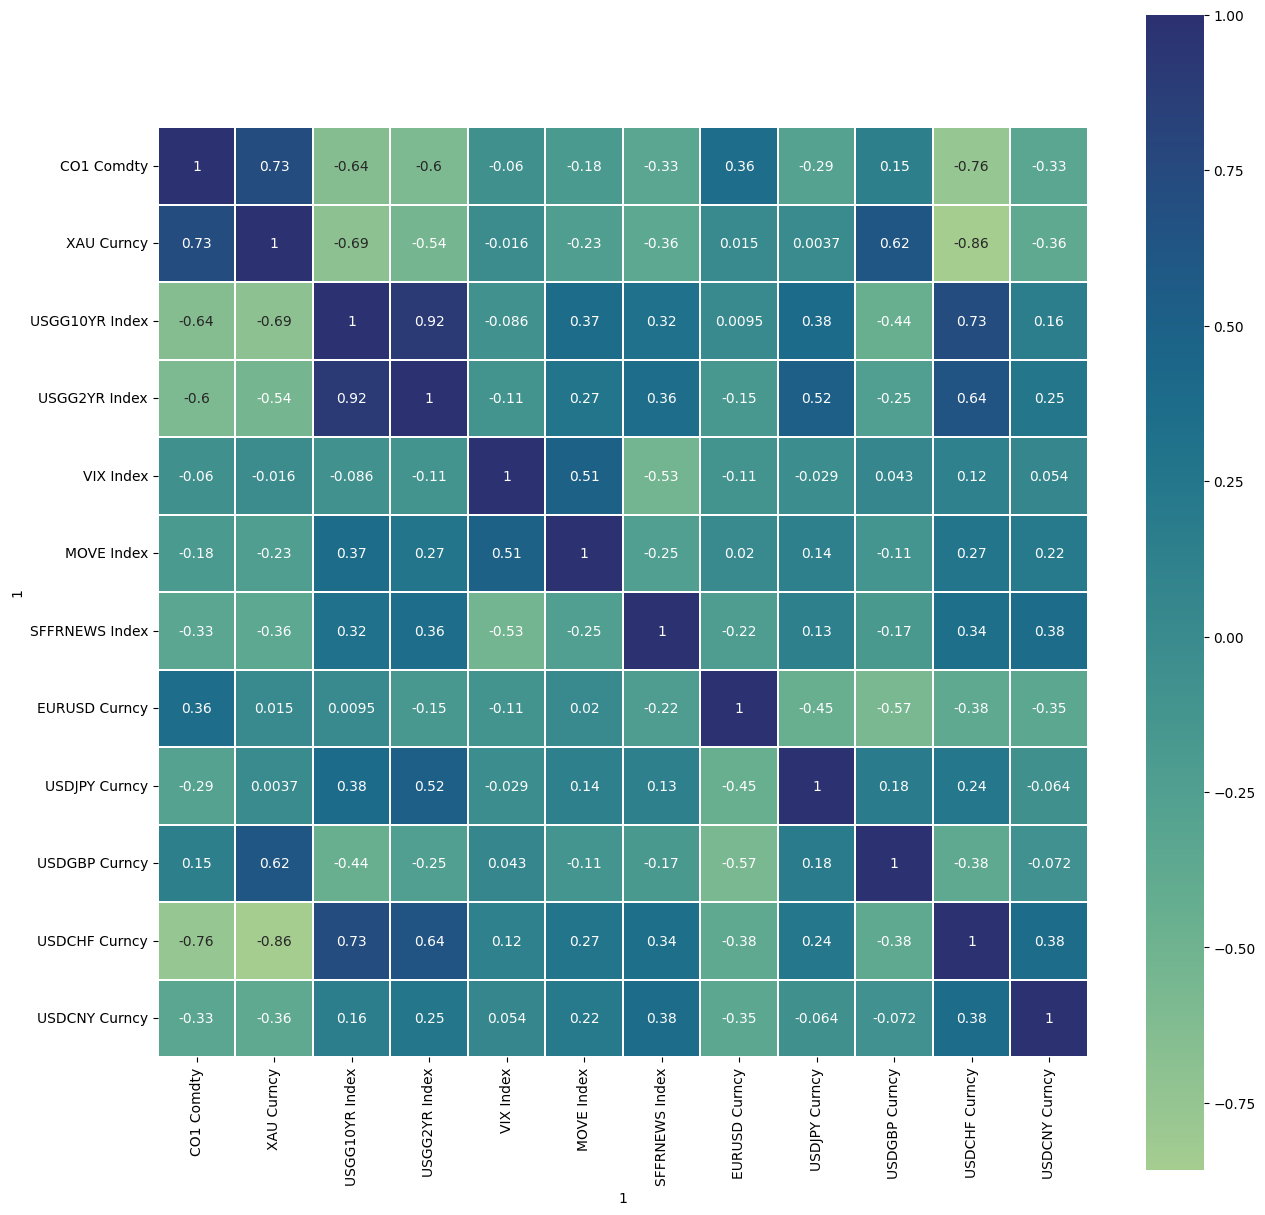

In [106]:
plt.figure(figsize=(15, 15))
sns.heatmap(data_indicators.corr(),square=True,linewidths=0.1,annot=True,cmap='crest')

<Axes: title={'center': 'Variance Inflation Factor'}>

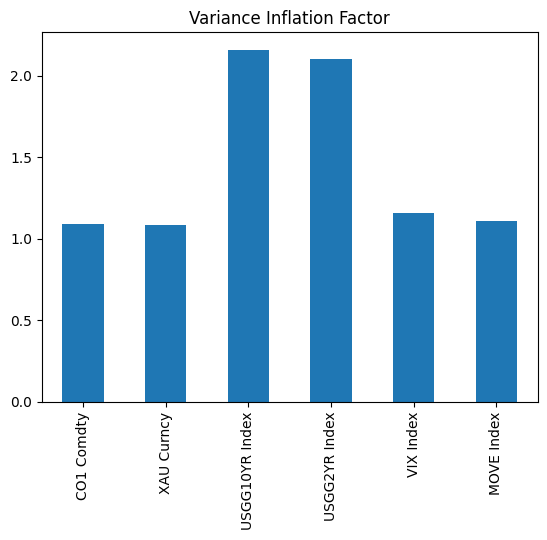

In [46]:
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant

def variance_inflation_factors(exog_df):
    '''
    Parameters
    ----------
    exog_df : dataframe, (nobs, k_vars)
        design matrix with all explanatory variables, as for example used in
        regression.

    Returns
    -------
    vif : Series
        variance inflation factors
    '''
    exog_df = add_constant(exog_df)
    vifs = pd.Series(
        [1 / (1. - OLS(exog_df[col].values, 
                       exog_df.loc[:, exog_df.columns != col].values).fit().rsquared) 
         for col in exog_df],
        index=exog_df.columns,
        name='VIF'
    )
    return vifs

variance_inflation_factors(data_indicators)[1:].plot(kind='bar',title='Variance Inflation Factor')

In [47]:
from sklearn.decomposition import PCA
pca = PCA(n_components=data_indicators.shape[1])
pca.fit(data_indicators)

PCA(n_components=6)

In [48]:
pca.explained_variance_ratio_

array([0.5610322 , 0.20179201, 0.14539896, 0.06080426, 0.02067528,
       0.0102973 ])

In [49]:
PCA_df = pd.DataFrame(pca.transform(X=data_indicators),columns=['PC'+str(idx+1) for idx in range(data_indicators.shape[1])],index=data_indicators.index)

100%|██████████| 1000/1000 [02:38<00:00,  6.30it/s]


No exogen transition


100%|██████████| 1000/1000 [03:32<00:00,  4.70it/s]


mu of dimension 2: will depend on delta


100%|██████████| 200/200 [01:30<00:00,  2.21it/s]


mu of dimension 2: will depend on delta


... (136 outputs left out)

100%|██████████| 200/200 [01:28<00:00,  2.26it/s]


mu of dimension 2: will depend on delta


100%|██████████| 8/8 [00:00<00:00, 16.00it/s]


defaultdict(<function __main__.calibrate_and_store.<locals>.<lambda>()>,
            {'SPX Index': {'PC1': {'data': array([[  5.09638835],
                      [  5.80537477],
                      [  1.82697534],
                      ...,
                      [-11.83344821],
                      [ -7.29190617],
                      [ -3.40137164]]),
               'eps': array([-0.25889081, -0.86503066, -0.98041386, ...,  2.48070343,
                       1.65238455,  0.7558982 ]),
               'target': 'SPX Index',
               'indicator': 'PC1',
               'initial_params': {'P': array([[0.98792576, 0.01207424],
                       [0.02378743, 0.97621257]]),
                'omega': array([0.44455905, 2.42397447]),
                'alpha': array([[0.        , 0.17830011]]),
                'pi_0': array([1.e-10, 1.e+00]),
                'log-likelihood': -12040.120902805154,
                'exogen_transition': array([[  5.09638835],
                       [  5.

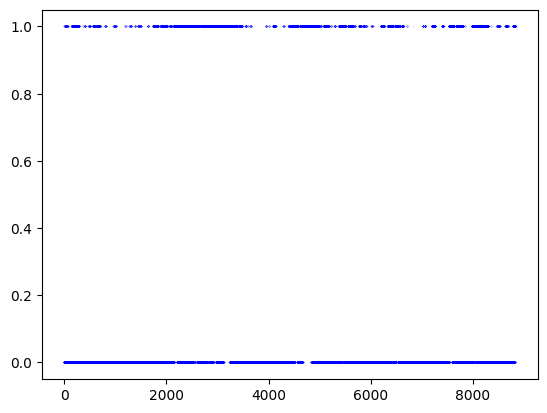

In [85]:
calibrate_and_store(pd.concat([data,PCA_df],axis=1),targets=targets,indicators=np.reshape(['PC1','PC2',*data_indicators.columns],(-1,1)),niter_HMM=1000,niter_MS=1000,niter_X=200,d=2,q=1)

# 3. Analyzing Results

For each pair of (target,indicator), we can look at several things:
- The repartition of states, we want the states to be somewhat persistent
- The log-likelihood as well as some information criteria (AIC, BIC)
- The Value-At-Risk Violation Rate as well as some VaR backtests
- Some vol strategy (but with one asset can it work?)
- The significancy of the beta, mu
- The graph of the evolution of calibration parameters through iterations

## Loading the Data

Version 1. Picking what to fetch

In [72]:
targets = ['SPX Index','CAC Index','DAX Index','SXXP Index','SX5E Index','NKY Index','RTY Index','NDX Index']
#fx = ['XBTUSD Curncy','EURUSD Curncy','USDGBP Curncy','USDJPY Curncy','USDCHF Curncy','USDCNY Curncy']
indicators = [col for col in data.columns if col not in targets]

In [267]:
with open(f"Datasets//Preprocessed_Data"+".pkl", "rb") as f:
    data = pickle.load(f)

In [20]:
# data = pd.read_excel(DATA / 'data.xlsx')
# new_header = data.iloc[1]
# description = data.iloc[0]
# data = data[2:]
# data.columns = new_header
# data.set_index('Dates', inplace=True)
# data.index = pd.to_datetime(data.index)
# data.sort_index(inplace=True)
# data = data.astype(float)

targets = ['SPX Index','CAC Index','DAX Index','SXXP Index','SX5E Index','NKY Index','RTY Index','NDX Index']
fx = ['XBTUSD Curncy','EURUSD Curncy','USDGBP Curncy','USDJPY Curncy','USDCHF Curncy','USDCNY Curncy']
indicators = ['PC1','PC2',*[col for col in data.columns if col not in targets and col not in fx]]

# Retrieving Results:
stored_data = defaultdict(lambda:{})
folder = "RealDataResults/"
for target in targets:
    for indicator in indicators:
        filename = f"{target}+{indicator}_results.pkl"
        full_path = os.path.join(folder, filename)
        
        if os.path.exists(full_path):
            with open(full_path, 'rb') as f:
                stored_data[target][indicator] = pickle.load(f)
        else:
            print(f"Fichier non trouvé pour {indicator}")

Fichier non trouvé pour PC1
Fichier non trouvé pour PC2
Fichier non trouvé pour PC1
Fichier non trouvé pour PC2
Fichier non trouvé pour PC1
Fichier non trouvé pour PC2
Fichier non trouvé pour PC1
Fichier non trouvé pour PC2
Fichier non trouvé pour PC1
Fichier non trouvé pour PC2
Fichier non trouvé pour PC1
Fichier non trouvé pour PC2
Fichier non trouvé pour PC1
Fichier non trouvé pour PC2
Fichier non trouvé pour PC1
Fichier non trouvé pour PC2


Version 2. Looking inside the Directory (with conditions)

In [73]:
stored_data = defaultdict(lambda: {})
folder = "RealDataResults_New2/"

# Parcours de tous les fichiers du dossier
for filename in os.listdir(folder):
    if filename.endswith("_results.pkl") and "+" in filename:
        try:
            # Extraire target et indicator depuis le nom de fichier
            core_name = filename.replace("_results.pkl", "")
            target, indicator = core_name.split("+", 1)
            
            # Charger le fichier
            full_path = os.path.join(folder, filename)
            with open(full_path, 'rb') as f:
                stored_data[target][indicator] = pickle.load(f)
        
        except Exception as e:
            print(f"Erreur lors du chargement de {filename} : {e}")


In [74]:
viable_indicators = list(stored_data['SPX Index'].keys())

## Log-Likelihood Analysis (AIC, BIC, LR Test)

In [75]:
Criterias = get_criteria_all(stored_data)

## Value-At-Risk Validation

#### Computing all Vars

In [76]:
Vars = compute_vars(stored_data)

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:54<00:00, 27.41s/it]


#### Computing Tests Results

In [77]:
Tests = var_tests(Vars)
Tests['Mean Violation Error'] = abs(Tests['Violation Rate'] - 0.05)

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00,  5.50it/s]


In [78]:
Results = pd.merge(Criterias.reset_index(),Tests.reset_index(),on=['indicator','target']).set_index('target')

In [23]:
full_sample_indicators = ['No Exogenous','USGG10YR Index','USGG2YR Index','VIX Index','SFFRNEWS Index','MOVE Index','CO1 Comdty','USDJPY Curncy']
Results.query('indicator in @full_sample_indicators').loc['SPX Index'].sort_values('mean Log-Likelihood')

## Sigma Backtest

In [79]:
with open(f"RealDataResults_New2//preprocessed_data"+".pkl", "rb") as f:
    data = pickle.load(f)

In [80]:
Sigmas = compute_sigma_backtest(stored_data)

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:08<00:00,  4.31s/it]


In [112]:
Results['sigma score'] = -Results['mean Log-Likelihood']

In [115]:
Results.sort_values('sigma score').query('indicator in @full_sample_indicators')

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,mean Log-Likelihood,sample size,mean AIC,mean BIC,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
24,SPX Index,SFFRNEWS Index,10,4,-11902.166196,23824.332391,23890.598247,275.909415,0.000000e+00,-1.347771,8831,2.697807,2.705311,0.052316,0.321528,0.796346,0.000847,0.123898,0.002316,1.347771
22,SPX Index,VIX Index,10,4,-12016.573021,24053.146041,24119.411897,47.095764,1.456461e-09,-1.360726,8831,2.723717,2.731221,0.052769,0.236576,0.843070,0.003791,0.126133,0.002769,1.360726
16,SPX Index,USGG2YR Index,10,4,-12032.506025,24085.012049,24151.277905,15.229757,4.247658e-03,-1.362530,8831,2.727326,2.734829,0.051863,0.424563,0.807733,0.000463,0.125958,0.001863,1.362530
8,SPX Index,CO1 Comdty,10,4,-12034.900328,24089.800656,24156.066511,10.441150,3.361736e-02,-1.362802,8831,2.727868,2.735372,0.051863,0.424563,0.756966,0.000949,0.126112,0.001863,1.362802
20,SPX Index,USGG10YR Index,10,4,-12035.631608,24091.263216,24157.529072,8.978589,6.163688e-02,-1.362884,8831,2.728033,2.735537,0.051750,0.453104,0.790118,0.000343,0.126122,0.001750,1.362884
26,SPX Index,MOVE Index,10,4,-12035.981122,24091.962244,24158.228100,8.279561,8.185792e-02,-1.362924,8831,2.728113,2.735616,0.052089,0.370791,0.686865,0.000636,0.125932,0.002089,1.362924
7,SPX Index,USDJPY Curncy,10,4,-12036.093849,24092.187698,24158.453554,8.054107,8.961616e-02,-1.362937,8831,2.728138,2.735642,0.051863,0.424563,0.799026,0.003490,0.125963,0.001863,1.362937
14,SPX Index,No Exogenous,6,0,-12040.120903,24092.241806,24132.001319,0.000000,NaN,-1.363393,8831,2.728144,2.732647,0.051750,0.453104,0.790118,0.000486,0.125967,0.001750,1.363393
60,CAC Index,SFFRNEWS Index,10,4,-13957.184812,27934.369623,27995.693750,216.250826,0.000000e+00,-1.580476,8831,3.163217,3.170161,0.054920,0.036635,0.165591,0.073706,0.145655,0.004920,1.580476
51,CAC Index,VIX Index,10,4,-14048.676853,28117.353707,28178.677834,33.266743,1.053305e-06,-1.590836,8831,3.183938,3.190882,0.055260,0.025624,0.636505,0.020043,0.147253,0.005260,1.590836


In [85]:
best_indicators = ['SFFRNEWS Index','USGG10YR Index','MOVE Index','VIX Index','No Exogenous']
target = 'CAC Index'

Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','Log-Likelihood','BIC','AIC','VaR loss','sigma score']].set_index('indicator').sort_values('BIC')
    

,Log-Likelihood,BIC,AIC,VaR loss,sigma score
indicator,,,,,
SFFRNEWS Index,-13957.184812,27995.693750,27934.369623,0.145655,8.346332
VIX Index,-14048.676853,28178.677834,28117.353707,0.147253,1.523478
No Exogenous,-14065.310225,28179.414925,28142.620449,0.147670,1.527317
USGG10YR Index,-14055.745881,28192.815889,28131.491762,0.147357,1.524294
USGG2YR Index,-14056.493050,28194.310227,28132.986100,0.147117,1.463170
CO1 Comdty,-14061.063093,28203.450314,28142.126187,0.147319,1.626222
MOVE Index,-14061.350043,28204.024212,28142.700085,0.147649,1.527608
USDJPY Curncy,-14063.161013,28207.646152,28146.322026,0.147654,1.524749


In [90]:
best_indicators = ['SFFRNEWS Index','USGG10YR Index','MOVE Index','VIX Index','No Exogenous']
target = 'CAC Index'

Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','mean Log-Likelihood','LR p-value','Log-Likelihood','BIC','AIC','VaR loss','sigma score']].set_index('indicator')
    

,mean Log-Likelihood,LR p-value,Log-Likelihood,BIC,AIC,VaR loss,sigma score
indicator,,,,,,,
USGG2YR Index,-1.591722,0.001455,-14056.493050,28194.310227,28132.986100,0.147117,1.463170
VIX Index,-1.590836,0.000001,-14048.676853,28178.677834,28117.353707,0.147253,1.523478
USGG10YR Index,-1.591637,0.000741,-14055.745881,28192.815889,28131.491762,0.147357,1.524294
USDJPY Curncy,-1.592477,0.367123,-14063.161013,28207.646152,28146.322026,0.147654,1.524749
No Exogenous,-1.592720,NaN,-14065.310225,28179.414925,28142.620449,0.147670,1.527317
MOVE Index,-1.592272,0.094539,-14061.350043,28204.024212,28142.700085,0.147649,1.527608
CO1 Comdty,-1.592239,0.075061,-14061.063093,28203.450314,28142.126187,0.147319,1.626222
SFFRNEWS Index,-1.580476,0.000000,-13957.184812,27995.693750,27934.369623,0.145655,8.346332


In [92]:
best_indicators = ['SFFRNEWS Index','USGG10YR Index','MOVE Index','VIX Index','No Exogenous']
target = 'SPX Index'

Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','mean Log-Likelihood','LR p-value','Log-Likelihood','BIC','AIC','VaR loss','sigma score']].set_index('indicator').sort_values('BIC')
    

,mean Log-Likelihood,LR p-value,Log-Likelihood,BIC,AIC,VaR loss,sigma score
indicator,,,,,,,
SFFRNEWS Index,-1.347771,0.000000e+00,-11902.166196,23890.598247,23824.332391,0.123898,8.485491
VIX Index,-1.360726,1.456461e-09,-12016.573021,24119.411897,24053.146041,0.126133,1.128441
No Exogenous,-1.363393,NaN,-12040.120903,24132.001319,24092.241806,0.125967,1.138112
USGG2YR Index,-1.362530,4.247658e-03,-12032.506025,24151.277905,24085.012049,0.125958,2.261776
CO1 Comdty,-1.362802,3.361736e-02,-12034.900328,24156.066511,24089.800656,0.126112,1.581915
USGG10YR Index,-1.362884,6.163688e-02,-12035.631608,24157.529072,24091.263216,0.126122,1.134253
MOVE Index,-1.362924,8.185792e-02,-12035.981122,24158.228100,24091.962244,0.125932,1.137156
USDJPY Curncy,-1.362937,8.961616e-02,-12036.093849,24158.453554,24092.187698,0.125963,1.126435


In [93]:
best_indicators = ['SFFRNEWS Index','USGG10YR Index','MOVE Index','VIX Index','No Exogenous']
target = 'CAC Index'

Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','mean Log-Likelihood','LR p-value','Log-Likelihood','BIC','AIC','VaR loss','sigma score']].set_index('indicator').sort_values('BIC')
    

,mean Log-Likelihood,LR p-value,Log-Likelihood,BIC,AIC,VaR loss,sigma score
indicator,,,,,,,
SFFRNEWS Index,-1.580476,0.000000,-13957.184812,27995.693750,27934.369623,0.145655,8.346332
VIX Index,-1.590836,0.000001,-14048.676853,28178.677834,28117.353707,0.147253,1.523478
No Exogenous,-1.592720,NaN,-14065.310225,28179.414925,28142.620449,0.147670,1.527317
USGG10YR Index,-1.591637,0.000741,-14055.745881,28192.815889,28131.491762,0.147357,1.524294
USGG2YR Index,-1.591722,0.001455,-14056.493050,28194.310227,28132.986100,0.147117,1.463170
CO1 Comdty,-1.592239,0.075061,-14061.063093,28203.450314,28142.126187,0.147319,1.626222
MOVE Index,-1.592272,0.094539,-14061.350043,28204.024212,28142.700085,0.147649,1.527608
USDJPY Curncy,-1.592477,0.367123,-14063.161013,28207.646152,28146.322026,0.147654,1.524749


In [103]:
Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','mean Log-Likelihood','LR p-value','Log-Likelihood','BIC','AIC','VaR loss','sigma score']].set_index('indicator').sort_values('BIC')

,mean Log-Likelihood,LR p-value,Log-Likelihood,BIC,AIC,VaR loss,sigma score
indicator,,,,,,,
SFFRNEWS Index,-1.580476,0.000000,-13957.184812,27995.693750,27934.369623,0.145655,8.346332
VIX Index,-1.590836,0.000001,-14048.676853,28178.677834,28117.353707,0.147253,1.523478
No Exogenous,-1.592720,NaN,-14065.310225,28179.414925,28142.620449,0.147670,1.527317
USGG10YR Index,-1.591637,0.000741,-14055.745881,28192.815889,28131.491762,0.147357,1.524294
USGG2YR Index,-1.591722,0.001455,-14056.493050,28194.310227,28132.986100,0.147117,1.463170
CO1 Comdty,-1.592239,0.075061,-14061.063093,28203.450314,28142.126187,0.147319,1.626222
MOVE Index,-1.592272,0.094539,-14061.350043,28204.024212,28142.700085,0.147649,1.527608
USDJPY Curncy,-1.592477,0.367123,-14063.161013,28207.646152,28146.322026,0.147654,1.524749


In [122]:
target = 'SPX Index'

In [135]:
Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','BIC','AIC','VaR loss','sigma score']].set_index('indicator')#.loc[['VIX Index','No Exogenous']].sort_values('BIC')

,BIC,AIC,VaR loss,sigma score
indicator,,,,
SFFRNEWS Index,23890.598247,23824.332391,0.123898,1.347771
VIX Index,24119.411897,24053.146041,0.126133,1.360726
USGG2YR Index,24151.277905,24085.012049,0.125958,1.362530
CO1 Comdty,24156.066511,24089.800656,0.126112,1.362802
USGG10YR Index,24157.529072,24091.263216,0.126122,1.362884
MOVE Index,24158.228100,24091.962244,0.125932,1.362924
USDJPY Curncy,24158.453554,24092.187698,0.125963,1.362937
No Exogenous,24132.001319,24092.241806,0.125967,1.363393


In [145]:
stored_data['SPX Index']['USGGY2R Index']['final_result']

In [147]:
indicator = 'USGG2YR Index'
stored_data['SPX Index'][indicator]['final_result']

{'P': array([[9.99731170e-01, 2.68829670e-04],
        [6.54079444e-02, 9.34592056e-01]]),
 'beta': array([[[-4.30950932],
         [ 4.30950932]],
 
        [[-1.211852  ],
         [ 1.211852  ]]]),
 'omega': array([0.44113848, 0.53117823]),
 'alpha': array([[1.58429052e-04, 1.78882477e-01]]),
 'mu': array([[0.        , 4.25687985]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -12032.506024530638,
 'exogen_transition': array([[0.38875035],
        [0.45247991],
        [0.45986885],
        ...,
        [0.38440935],
        [0.38884271],
        [0.49930729]]),
 'exogen_additive': array([[0.38875035],
        [0.45247991],
        [0.45986885],
        ...,
        [0.38440935],
        [0.38884271],
        [0.49930729]]),
 'mean log-likelihood': -1.3625304070355155}

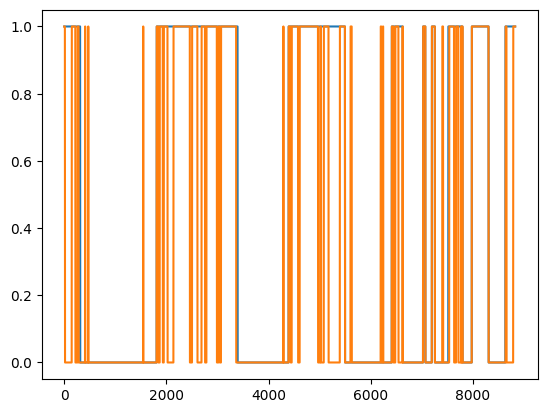

In [149]:
plt.plot(stored_data['SPX Index'][indicator]['states sequence'])#['state sequence']
plt.plot(stored_data['SPX Index']['No Exogenous']['states sequence'])#['state sequence']


In [ ]:
Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','mean Log-Likelihood','Log-Likelihood','BIC','AIC','VaR loss','sigma score']].set_index('indicator').loc[['VIX Index','No Exogenous']].sort_values('BIC')

,mean Log-Likelihood,Log-Likelihood,BIC,AIC,VaR loss,sigma score
indicator,,,,,,
VIX Index,-1.590836,-14048.676853,28178.677834,28117.353707,0.147253,1.590836
No Exogenous,-1.592720,-14065.310225,28179.414925,28142.620449,0.147670,1.592720


In [116]:
stored_data['SPX Index']['VIX Index']['final_result']['beta']

array([[[ 4.78287908],
        [-4.78287908]],

       [[ 7.81367545],
        [-7.81367545]]])

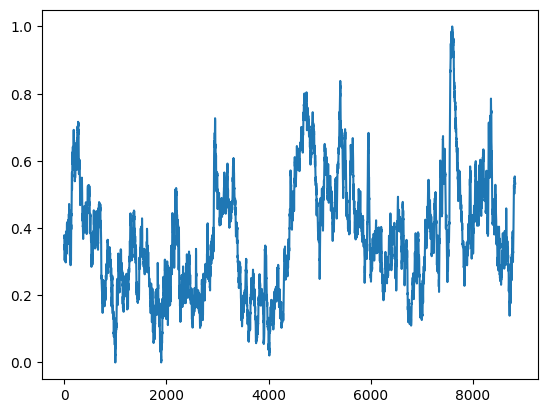

In [100]:
plt.plot(stored_data['SPX Index']['SFFRNEWS Index']['data'])

In [98]:
stored_data['SPX Index']['SFFRNEWS Index']['final_result']['beta']

array([[[-0.78027206],
        [ 0.78027206]],

       [[ 0.28361389],
        [-0.28361389]]])

In [ ]:
stored_data['SPX Index']['VIX Index']['final_result']

array([[[ 4.78287908],
        [-4.78287908]],

       [[ 7.81367545],
        [-7.81367545]]])

In [ ]:
best_indicators = ['SFFRNEWS Index','USGG10YR Index','MOVE Index','VIX Index','No Exogenous']
target = 'CAC Index'

Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','Log-Likelihood','BIC','AIC','VaR loss']].set_index('indicator')
    

,Log-Likelihood,BIC,AIC,VaR loss,sigma score
indicator,,,,,
MOVE Index,-14011.581603,28104.487333,28043.163206,0.147099,1.387351
SFFRNEWS Index,-14036.884720,28155.093567,28093.769440,0.146765,1.432944
VIX Index,-13836.736465,27754.797056,27693.472929,0.141365,1.451307
USGG10YR Index,-14033.267134,28147.858396,28086.534269,0.146188,1.458547
USDJPY Curncy,-14038.665273,28158.654674,28097.330547,0.146987,1.482689
USGG2YR Index,-14041.093919,28163.511965,28102.187839,0.146250,1.484974
CO1 Comdty,-14057.006568,28195.337263,28134.013136,0.147592,1.501435
No Exogenous,-14065.310225,28179.414925,28142.620449,0.147670,1.527317


In [111]:
best_indicators = ['SFFRNEWS Index','USGG10YR Index','MOVE Index','VIX Index','No Exogenous']
target = 'CAC Index'

Results.query('indicator in @full_sample_indicators').query('target == @target').sort_values('sigma score')[['indicator','Log-Likelihood','BIC','AIC','VaR loss']].set_index('indicator')
    

,Log-Likelihood,BIC,AIC,VaR loss
indicator,,,,
USGG2YR Index,-14056.493050,28194.310227,28132.986100,0.147117
VIX Index,-14048.676853,28178.677834,28117.353707,0.147253
USGG10YR Index,-14055.745881,28192.815889,28131.491762,0.147357
USDJPY Curncy,-14063.161013,28207.646152,28146.322026,0.147654
No Exogenous,-14065.310225,28179.414925,28142.620449,0.147670
MOVE Index,-14061.350043,28204.024212,28142.700085,0.147649
CO1 Comdty,-14061.063093,28203.450314,28142.126187,0.147319
SFFRNEWS Index,-13957.184812,27995.693750,27934.369623,0.145655


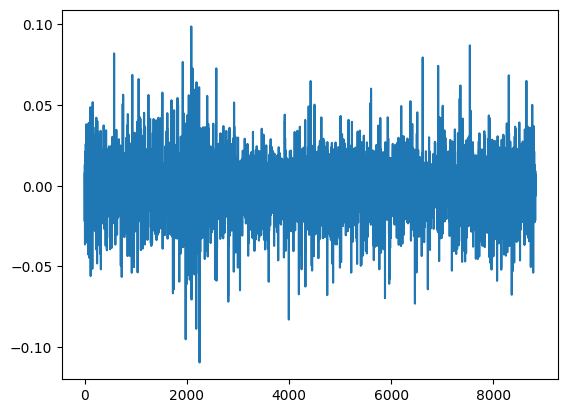

In [86]:
plt.plot(np.diff(stored_data['CAC Index']['SFFRNEWS Index']['data'].reshape(-1)))

In [89]:
Results.sort_values(['sample size']).set_index('target').loc['CAC Index'].iloc[-13:].sort_values('BIC').iloc[:6]#sort_values('mean Log-Likelihood')

,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,mean Log-Likelihood,sample size,mean AIC,mean BIC,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
target,,,,,,,,,,,,,,,,,,,
CAC Index,SFFRNEWS Index,10,4,-13957.184812,27934.369623,27995.693750,216.250826,0.000000,-1.580476,8831,3.163217,3.170161,0.054920,0.036635,0.165591,0.073706,0.145655,0.004920,8.346332
CAC Index,VIX Index,10,4,-14048.676853,28117.353707,28178.677834,33.266743,0.000001,-1.590836,8831,3.183938,3.190882,0.055260,0.025624,0.636505,0.020043,0.147253,0.005260,1.523478
CAC Index,No Exogenous,6,0,-14065.310225,28142.620449,28179.414925,0.000000,NaN,-1.592720,8831,3.186799,3.190965,0.055713,0.015485,0.295127,0.000830,0.147670,0.005713,1.527317
CAC Index,USGG10YR Index,10,4,-14055.745881,28131.491762,28192.815889,19.128687,0.000741,-1.591637,8831,3.185539,3.192483,0.056053,0.010400,0.518764,0.000982,0.147357,0.006053,1.524294
CAC Index,USGG2YR Index,10,4,-14056.493050,28132.986100,28194.310227,17.634349,0.001455,-1.591722,8831,3.185708,3.192652,0.055147,0.028922,0.322923,0.004269,0.147117,0.005147,1.463170
CAC Index,EURUSD Curncy,10,4,-14059.322882,28138.645765,28199.969891,11.974685,0.017541,-1.592042,8831,3.186349,3.193293,0.055600,0.017614,0.781333,0.019935,0.147636,0.005600,1.706868


In [65]:
Results.sort_values(['sample size']).iloc[-12:].sort_values('BIC')

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,mean Log-Likelihood,sample size,mean AIC,mean BIC,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
22,SPX Index,VIX Index,10,4,-11662.354288,23344.708576,23410.970846,755.533229,0.000000e+00,-1.320615,8831,2.643495,2.650999,0.056505,0.005953,0.872312,0.000403,0.120262,0.006505,2.029439
24,SPX Index,SFFRNEWS Index,10,4,-11957.154799,23934.309597,24000.571867,165.932209,0.000000e+00,-1.353998,8831,2.710260,2.717764,0.054580,0.051477,0.972808,0.008275,0.125074,0.004580,1.390633
26,SPX Index,MOVE Index,10,4,-11984.079411,23988.158822,24054.421092,112.082984,0.000000e+00,-1.357047,8831,2.716358,2.723862,0.052995,0.200713,0.743401,0.001034,0.125189,0.002995,1.146226
6,SPX Index,USDGBP Curncy,10,4,-12013.775468,24047.550936,24113.813205,52.690870,9.890266e-11,-1.360563,8830,2.723392,2.730896,0.052095,0.369477,0.831302,0.000062,0.125598,0.002095,1.115554
30,SPX Index,EURUSD Curncy,10,4,-12018.168799,24056.337597,24122.599867,43.904209,6.716527e-09,-1.361061,8830,2.724387,2.731891,0.052548,0.275720,0.837179,0.000400,0.125339,0.002548,1.141749
21,SPX Index,XAU Curncy,10,4,-12019.103696,24058.207392,24124.469662,42.034413,1.640988e-08,-1.361167,8830,2.724599,2.732103,0.051982,0.395749,0.798994,0.001042,0.125789,0.001982,1.148596
8,SPX Index,CO1 Comdty,10,4,-12019.457489,24058.914977,24125.177247,41.326828,2.299959e-08,-1.361207,8830,2.724679,2.732183,0.052548,0.275720,0.837179,0.003499,0.125794,0.002548,1.179272
14,SPX Index,No Exogenous,6,0,-12040.120903,24092.241806,24131.999167,0.000000,NaN,-1.363393,8831,2.728144,2.732646,0.051750,0.453104,0.790118,0.000486,0.125967,0.001750,1.138112
7,SPX Index,USDJPY Curncy,10,4,-12027.080000,24074.159999,24140.422269,26.081807,3.046511e-05,-1.362070,8830,2.726405,2.733910,0.051982,0.395749,0.798994,0.000589,0.125947,0.001982,1.118763
20,SPX Index,USGG10YR Index,10,4,-12028.039104,24076.078208,24142.340477,24.163598,7.406429e-05,-1.362025,8831,2.726314,2.733817,0.051070,0.645619,0.660365,0.000414,0.125880,0.001070,1.189666


In [28]:
display(Results.sort_values(['target','VaR loss']).query('target == "SPX Index"').sort_values('VaR loss'))

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,mean Log-Likelihood,sample size,mean AIC,mean BIC,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
9,SPX Index,CDX HY CDSI GEN 5Y SPRD Corp,10,4,-4048.449541,8116.899083,8183.166731,16126.661066,0.000000e+00,-1.274701,3176,2.555699,2.576564,0.050693,0.858152,0.475375,0.109934,0.120441,0.000693,0.878861
15,SPX Index,ITRX EUR CDSI GEN 5Y Corp,10,4,-4365.657564,8751.315129,8817.582777,15492.245020,0.000000e+00,-1.290851,3382,2.587615,2.607210,0.052632,0.486126,0.392443,0.127518,0.120880,0.002632,0.896487
5,SPX Index,CDX IG CDSI GEN 5Y Corp,10,4,-4413.159490,8846.318980,8912.586628,15397.241169,0.000000e+00,-1.296463,3404,2.598801,2.618269,0.052291,0.542486,0.396998,0.167519,0.121518,0.002291,0.931066
23,SPX Index,ITRX XOVER CDSI GEN 5Y Corp,10,4,-4416.989770,8853.979541,8920.247189,15389.580608,0.000000e+00,-1.297588,3404,2.601052,2.620519,0.052585,0.492381,0.392286,0.190231,0.121670,0.002585,0.919732
21,SPX Index,SFFRNEWS Index,10,4,-11937.794516,23895.589032,23961.856681,347.971116,0.000000e+00,-1.351806,8831,2.705876,2.713380,0.052655,0.256136,0.453357,0.062209,0.123806,0.002655,1.082355
18,SPX Index,XAU Curncy,10,4,-12060.995601,24141.991202,24208.258851,101.568947,0.000000e+00,-1.365756,8831,2.733778,2.741282,0.053335,0.154683,0.529333,0.007212,0.127112,0.003335,1.052443
6,SPX Index,CO1 Comdty,10,4,-12069.026449,24158.052898,24224.320546,85.507251,0.000000e+00,-1.366666,8831,2.735597,2.743101,0.053222,0.169029,0.143683,0.010225,0.127117,0.003222,1.059386
14,SPX Index,USGG2YR Index,10,4,-12080.630489,24181.260978,24247.528626,62.299171,9.530154e-13,-1.367980,8831,2.738225,2.745729,0.052995,0.200713,0.152521,0.014284,0.127185,0.002995,1.080652
17,SPX Index,USGG10YR Index,10,4,-12082.279644,24184.559287,24250.826936,59.000862,4.703571e-12,-1.368167,8831,2.738598,2.746102,0.052316,0.321528,0.114676,0.009493,0.127207,0.002316,1.083248
4,SPX Index,GTDEM2Y Govt,10,4,-11845.759397,23711.518794,23777.786442,532.041355,0.000000e+00,-1.368977,8653,2.740266,2.747924,0.052352,0.319027,0.135961,0.005471,0.127710,0.002352,1.067426


In [29]:
display(Results.sort_values(['target','VaR loss']).query('target == "CAC Index"').sort_values('VaR loss'))

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,mean Log-Likelihood,sample size,mean AIC,mean BIC,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
9,SPX Index,CDX HY CDSI GEN 5Y SPRD Corp,10,4,-4048.449541,8116.899083,8183.166731,16126.661066,0.000000e+00,-1.274701,3176,2.555699,2.576564,0.050693,0.858152,0.475375,0.109934,0.120441,0.000693,0.878861
15,SPX Index,ITRX EUR CDSI GEN 5Y Corp,10,4,-4365.657564,8751.315129,8817.582777,15492.245020,0.000000e+00,-1.290851,3382,2.587615,2.607210,0.052632,0.486126,0.392443,0.127518,0.120880,0.002632,0.896487
5,SPX Index,CDX IG CDSI GEN 5Y Corp,10,4,-4413.159490,8846.318980,8912.586628,15397.241169,0.000000e+00,-1.296463,3404,2.598801,2.618269,0.052291,0.542486,0.396998,0.167519,0.121518,0.002291,0.931066
23,SPX Index,ITRX XOVER CDSI GEN 5Y Corp,10,4,-4416.989770,8853.979541,8920.247189,15389.580608,0.000000e+00,-1.297588,3404,2.601052,2.620519,0.052585,0.492381,0.392286,0.190231,0.121670,0.002585,0.919732
21,SPX Index,SFFRNEWS Index,10,4,-11937.794516,23895.589032,23961.856681,347.971116,0.000000e+00,-1.351806,8831,2.705876,2.713380,0.052655,0.256136,0.453357,0.062209,0.123806,0.002655,1.082355
18,SPX Index,XAU Curncy,10,4,-12060.995601,24141.991202,24208.258851,101.568947,0.000000e+00,-1.365756,8831,2.733778,2.741282,0.053335,0.154683,0.529333,0.007212,0.127112,0.003335,1.052443
6,SPX Index,CO1 Comdty,10,4,-12069.026449,24158.052898,24224.320546,85.507251,0.000000e+00,-1.366666,8831,2.735597,2.743101,0.053222,0.169029,0.143683,0.010225,0.127117,0.003222,1.059386
14,SPX Index,USGG2YR Index,10,4,-12080.630489,24181.260978,24247.528626,62.299171,9.530154e-13,-1.367980,8831,2.738225,2.745729,0.052995,0.200713,0.152521,0.014284,0.127185,0.002995,1.080652
17,SPX Index,USGG10YR Index,10,4,-12082.279644,24184.559287,24250.826936,59.000862,4.703571e-12,-1.368167,8831,2.738598,2.746102,0.052316,0.321528,0.114676,0.009493,0.127207,0.002316,1.083248
4,SPX Index,GTDEM2Y Govt,10,4,-11845.759397,23711.518794,23777.786442,532.041355,0.000000e+00,-1.368977,8653,2.740266,2.747924,0.052352,0.319027,0.135961,0.005471,0.127710,0.002352,1.067426


## Retrieving States

In [100]:
def compute_viterbi(stored_data,targets=None):
    if targets is None:
        targets = stored_data.keys()
    for target in tqdm(targets):
        for indicator in tqdm(stored_data[target].keys()):
            result_with_exogen = deepcopy(stored_data[target][indicator]['final_result'])
            result_with_exogen['exogen_transition'] = stored_data[target][indicator]['result'][0].get('exogen_transition', None)
            stored_data[target][indicator]['viterbi'] = viterbi_continuous(stored_data[target][indicator]['eps'],stored_data[target][indicator]['final_result'])
    return stored_data

In [101]:
#plt.plot(viterbi_continuous(stored_data[target][indicator]['eps'],stored_data[target][indicator]['result'][1]),linestyle='',marker='o',color='b')
#plt.plot(viterbi_continuous(stored_data[target][indicator]['eps'][1:],stored_data[target][indicator]['result'][0]),linestyle='',marker='o',color='r')

np.mean(np.abs(viterbi_continuous(stored_data[target][indicator]['eps'][:-1],stored_data[target][indicator]['result'][1])-viterbi_continuous(stored_data[target][indicator]['eps'][:-1],stored_data[target][indicator]['result'][0])))

No exogen transition


0.03782559456398641

## Putting it all together

[Text(0.5, 1.0, 'CAC Index'),
 Text(0.5, 1.0, 'DAX Index'),
 Text(0.5, 1.0, 'NDX Index'),
 Text(0.5, 1.0, 'NKY Index'),
 Text(0.5, 1.0, 'RTY Index'),
 Text(0.5, 1.0, 'SPX Index'),
 Text(0.5, 1.0, 'SX5E Index'),
 Text(0.5, 1.0, 'SXXP Index')]

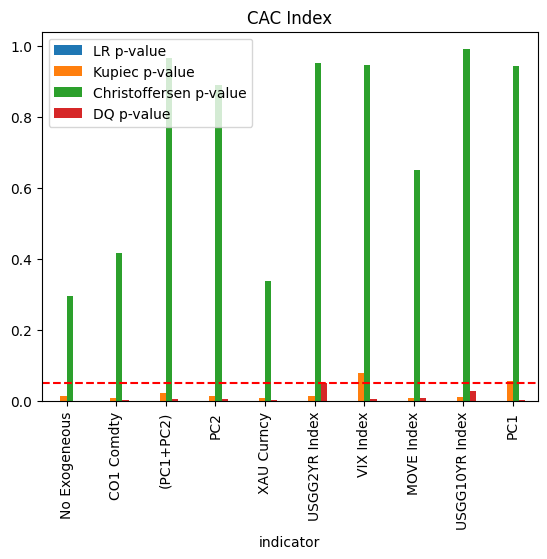

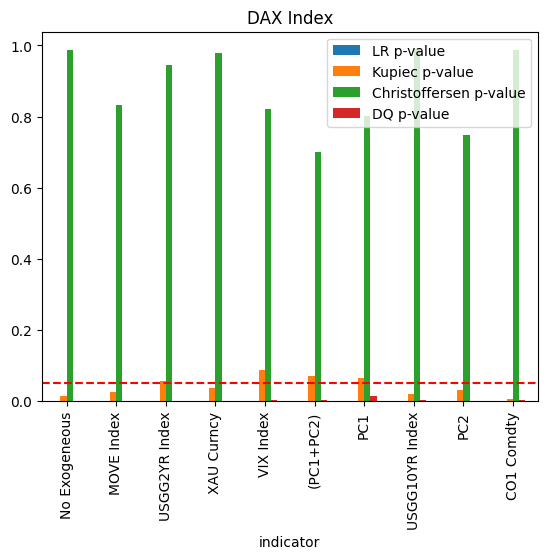

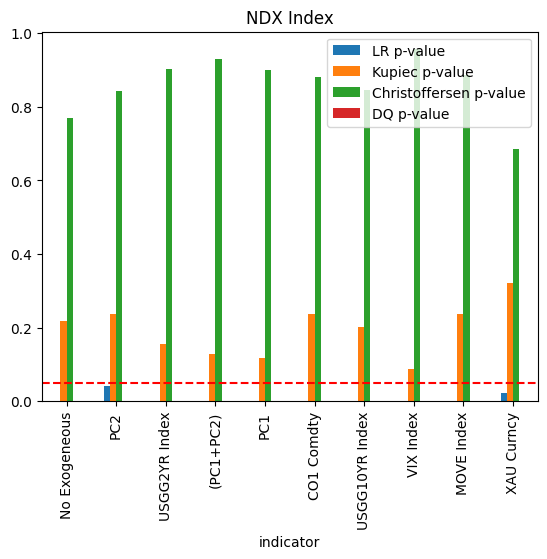

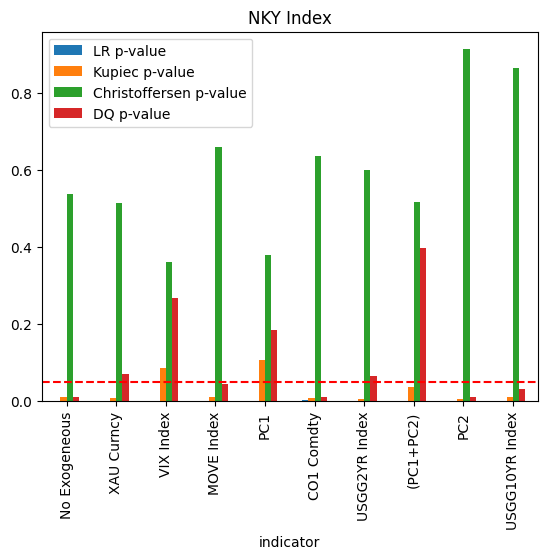

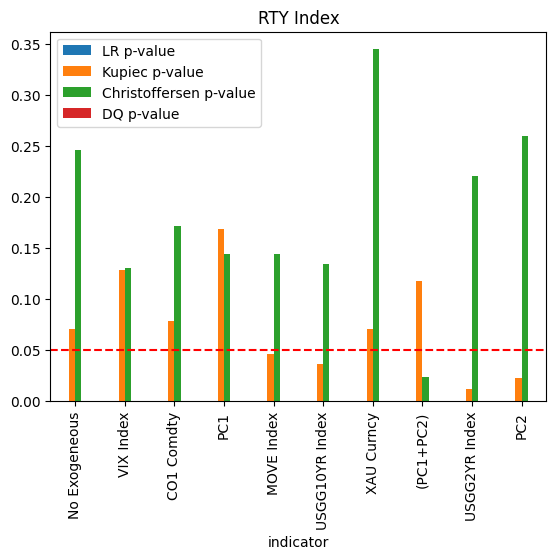

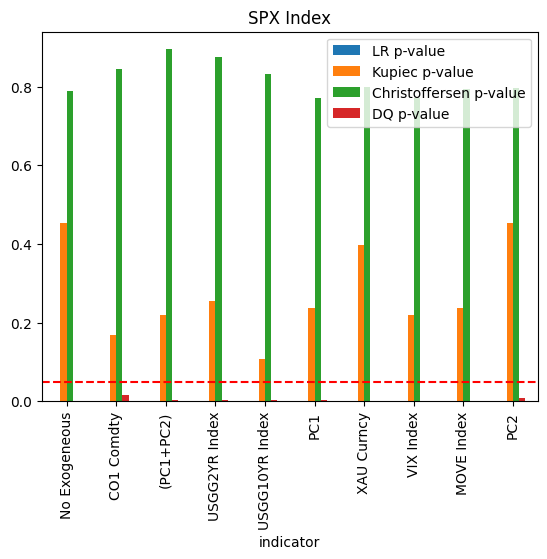

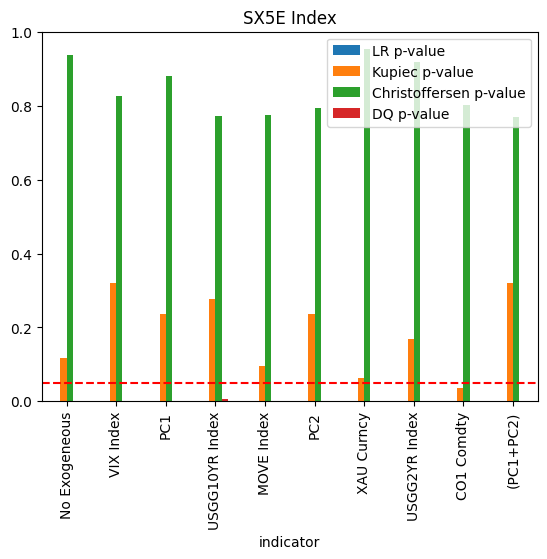

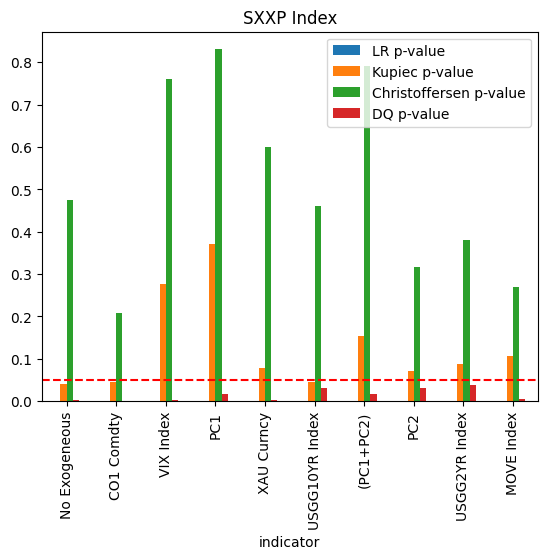

In [54]:
### p-values plot
axs = Results.round(4).groupby('target').plot(kind='bar',y=[col for col in Results.columns if col.split(' ')[-1]=='p-value'],x='indicator')
[ax.axhline(y=0.05,linestyle='--',color='red') for ax in axs]
[ax.set_title(target) for (target,_),ax in zip(Results.groupby('target'),axs)]

In [102]:
rankings = get_rank(Results,Columns=[col for col in Results.columns if col not in ['target','indicator','df','excess df','LR stat','Violation Rate']],method='mean')

In [103]:
rankings.median(axis=1).sort_values()

indicator
PC1               3.03125
VIX Index         3.06250
USGG10YR Index    3.43750
USGG2YR Index     4.00000
XAU Curncy        5.37500
No Exogeneous     5.75000
CO1 Comdty        6.00000
MOVE Index        6.00000
PC2               6.62500
dtype: float64

<Axes: >

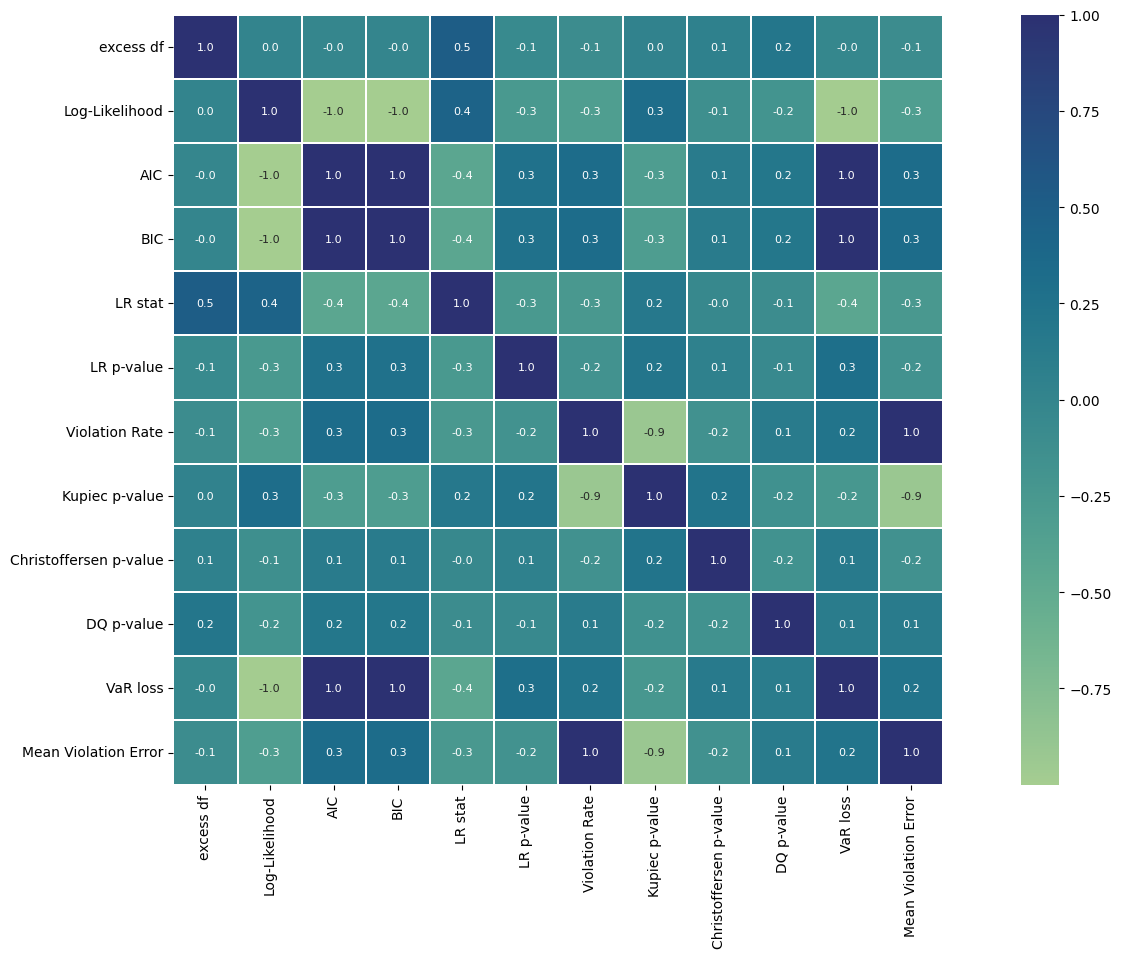

In [ ]:
plt.figure(figsize=(20,10))
#mask = np.triu(np.ones(Results.drop(columns=['indicator','df']).corr().shape), k=1)
sns.heatmap(Results.drop(columns=['indicator','df']).corr(),cmap='crest',square=True,linewidths=0.1,annot=True,annot_kws={"size": 8},fmt='.1f')#,mask=mask)

<Axes: >

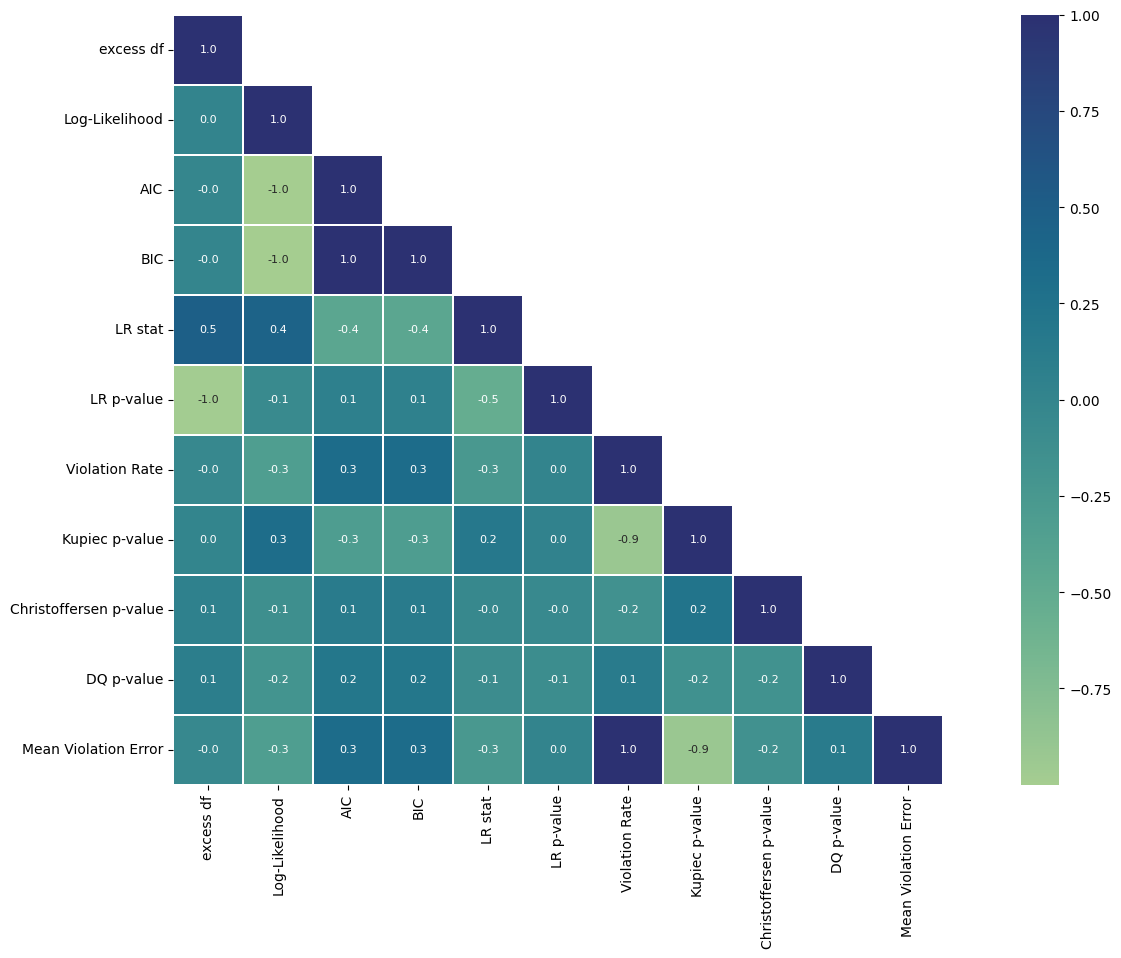

In [ ]:
plt.figure(figsize=(20,10))
#mask = np.triu(np.ones(Results.drop(columns=['indicator','df']).corr().shape), k=1)
sns.heatmap(Results.drop(columns=['indicator','df']).corr(),cmap='crest',square=True,linewidths=0.1,annot=True,annot_kws={"size": 8},fmt='.1f',mask=mask)

In [105]:
Results

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
0,SXXP Index,No Exogeneous,6,0,-12006.610221,24025.220441,24067.736582,0.000000,NaN,0.054807,0.041112,0.473977,3.568058e-03,0.124562,0.004807,1.126403
1,SXXP Index,CO1 Comdty,10,4,-11992.220776,24004.441551,24075.301787,28.778890,8.668949e-06,0.054807,0.041112,0.289874,6.522255e-03,0.124310,0.004807,1.133068
2,SXXP Index,VIX Index,10,4,-11920.755970,23861.511940,23932.372175,171.708501,0.000000e+00,0.052089,0.370791,0.691510,3.871095e-03,0.121932,0.002089,1.136055
3,SXXP Index,PC1,10,4,-11921.084811,23862.169622,23933.029858,171.050819,0.000000e+00,0.052655,0.256136,0.840681,1.456213e-02,0.121935,0.002655,1.140373
4,SXXP Index,XAU Curncy,10,4,-11992.882749,24005.765497,24076.625733,27.454944,1.608285e-05,0.053901,0.096517,0.463697,1.051106e-03,0.124463,0.003901,1.136620
5,SXXP Index,USGG10YR Index,10,4,-11954.442676,23928.885351,23999.745587,104.335090,0.000000e+00,0.054354,0.063963,0.419691,2.095484e-02,0.122953,0.004354,1.139346
6,SXXP Index,PC2,10,4,-11998.256099,24016.512199,24087.372434,16.708242,2.202187e-03,0.055713,0.015485,0.584195,8.254467e-03,0.123883,0.005713,1.126583
7,SXXP Index,USGG2YR Index,10,4,-11959.072768,23938.145537,24009.005772,95.074904,0.000000e+00,0.053675,0.117218,0.259698,2.472839e-03,0.122642,0.003675,1.137231
8,SXXP Index,MOVE Index,10,4,-11996.952188,24013.904377,24084.764612,19.316064,6.811566e-04,0.054241,0.071095,0.406314,3.204459e-03,0.124205,0.004241,1.130200
9,SX5E Index,No Exogeneous,6,0,-13613.710162,27239.420323,27281.936464,0.000000,NaN,0.053675,0.117218,0.937455,2.762155e-05,0.147906,0.003675,1.477012


### Algo Convergence Plots

### Retrieving States

Text(0.5, 1.0, 'eps vs +/- sigma')

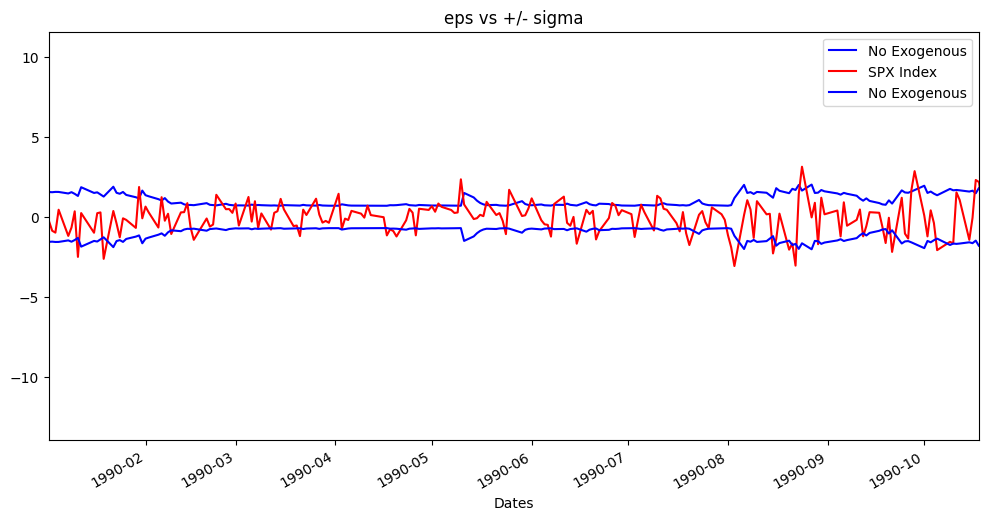

In [ ]:
target = 'SPX Index'
indicator = 'No Exogeneous'
ax = pd.DataFrame(np.sqrt(res[target]['No Exogeneous']),columns=['No Exogenous'],index=data.iloc[:-1].index).plot(label=indicator,figsize=(12,6),color='b')
ax.plot(data[target].iloc[:-1],label=target,color='r')
pd.DataFrame(-np.sqrt(res[target]['No Exogeneous']),columns=['No Exogenous'],index=data.iloc[:-1].index).plot(figsize=(12,6),color='b',ax=ax)
plt.xlim(data.index[0],data.index[200])
ax.legend()
plt.title('eps vs +/- sigma')

Text(0.5, 1.0, 'eps vs +/- sigma')

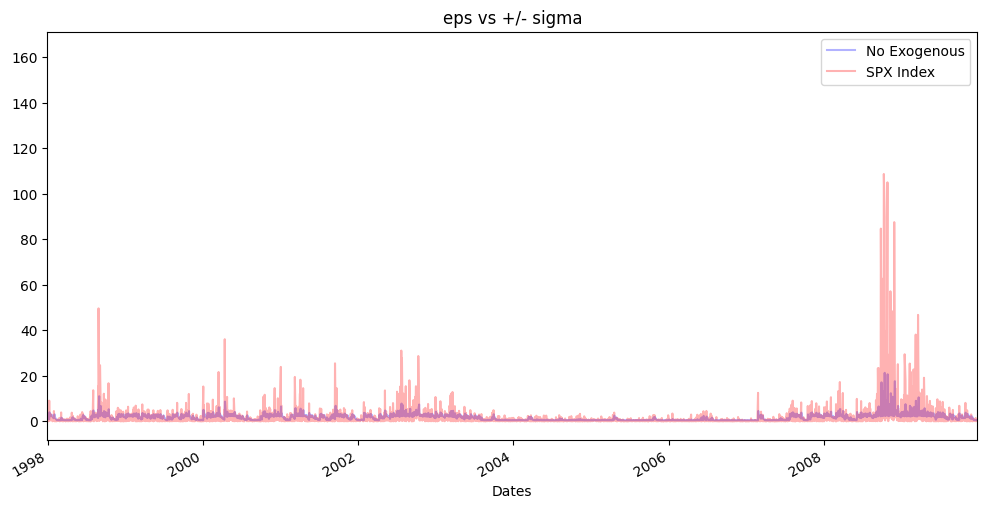

In [ ]:
target = 'SPX Index'
indicator = 'No Exogeneous'
ax = pd.DataFrame(res[target]['No Exogeneous'],columns=['No Exogenous'],index=data.iloc[:-1].index).plot(label=indicator,figsize=(12,6),color='b',alpha=0.3)
ax.plot(data[target].iloc[:-1]**2,label=target,color='r',alpha=0.3)
#pd.DataFrame(-np.sqrt(res[target]['No Exogeneous']),columns=['No Exogenous'],index=data.iloc[:-1].index).plot(figsize=(12,6),color='b',ax=ax)
plt.xlim(data.index[2000],data.index[5000])
ax.legend()
plt.title('eps vs +/- sigma')

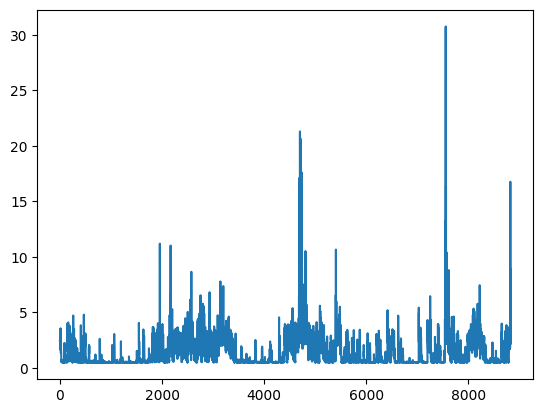

In [ ]:
plt.plot(res['SPX Index']['No Exogeneous'])

In [ ]:
Vars['SPX Index']['CO1 Comdty']

{'data': array([[ 5.59387528],
        [-0.83333816],
        [ 2.25245101],
        ...,
        [ 1.76519168],
        [-1.97670407],
        [ 0.4526943 ]]),
 'constrained': array([-2.56089181, -2.54895896, -2.58995026, ..., -3.02710891,
        -3.06444168, -2.78247237]),
 'with exogen': array([-2.34259605, -2.93441951, -2.45315194, ..., -3.02777439,
        -2.98120022, -2.76349455]),
 'eps': array([-0.25889081, -0.86503066, -0.98041386, ...,  2.48070343,
         1.65238455,  0.7558982 ]),
 'violation constrained': array([False, False, False, ..., False, False, False]),
 'violation with exogen': array([False, False, False, ..., False, False, False])}

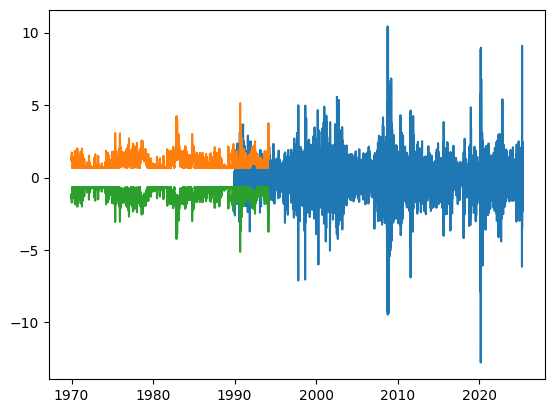

In [ ]:
plt.plot(data['SPX Index'])
plt.plot(np.sqrt(res['SPX Index']['CO1 Comdty']))
plt.plot(-np.sqrt(res['SPX Index']['CO1 Comdty']))

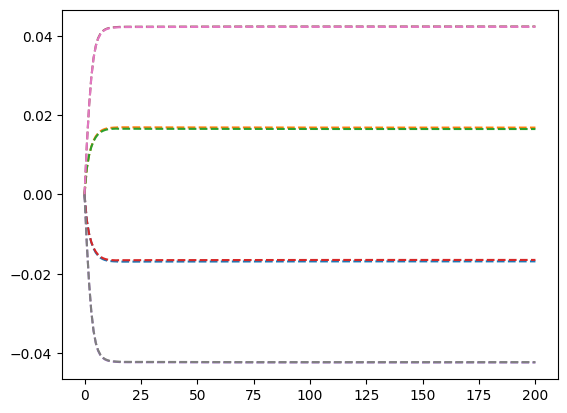

In [ ]:
for i in range(2):
    for j in range(2):
        plt.plot([stored_data['CAC Index']['(PC1+PC2)']['result'][idx]['beta'][i,j] for idx in stored_data['CAC Index']['(PC1+PC2)']['result'].keys()],linestyle='--')

In [ ]:

for target in targets[:2]:
    for indicator in viable_indicators:
        results = copy(stored_data[target][viable_indicators[0]]['result'])
        results[0] = {key:value for key,value in results[0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive']}
        #result_exogen[0].pop('mu_depends_on_delta')
        df_exo = convert_dict_to_dataframe(results)
        fig,axs = plt.subplots(2,3,figsize=(12,12))
        plt.suptitle(f'{target} + {indicator}')
        for idx,start in enumerate(['P','omega','alpha','beta','mu']):
            ax = axs[idx//3,idx%3]
            df_exo.loc[:200].plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6),ax=ax)
            ax.set_title(start)
        fig.delaxes(axs[1,2])
        plt.tight_layout()
        plt.show()

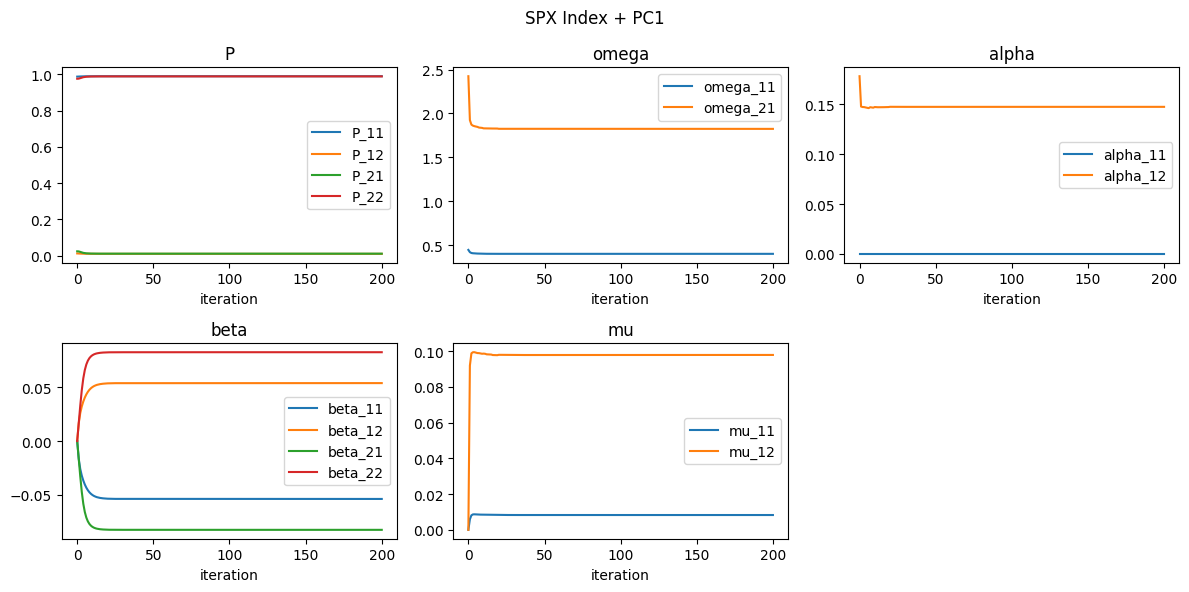

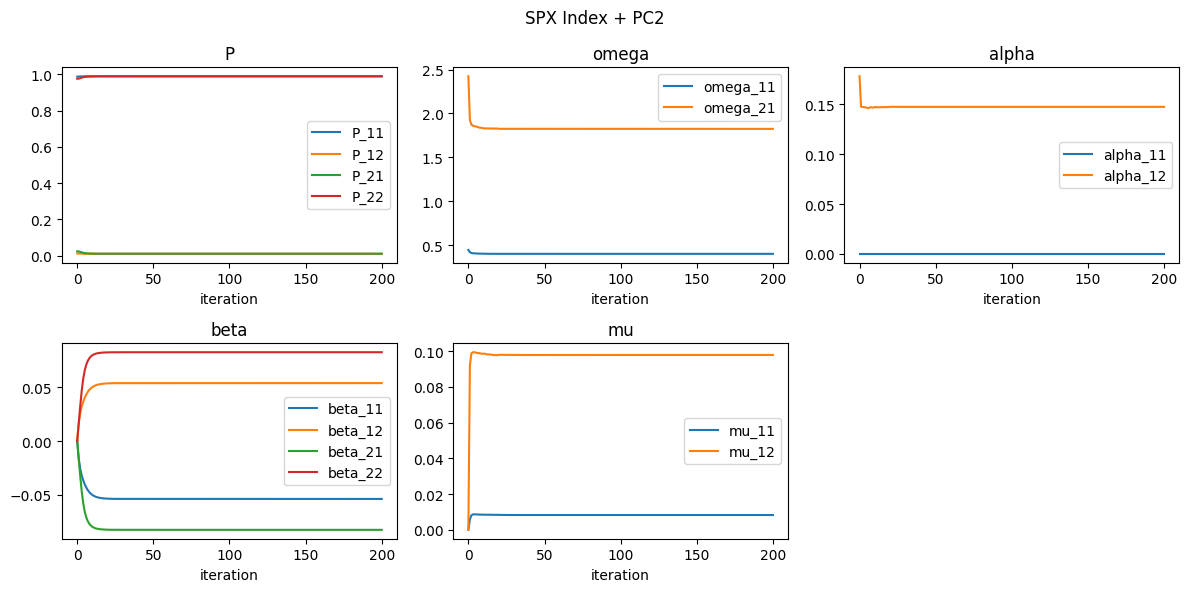

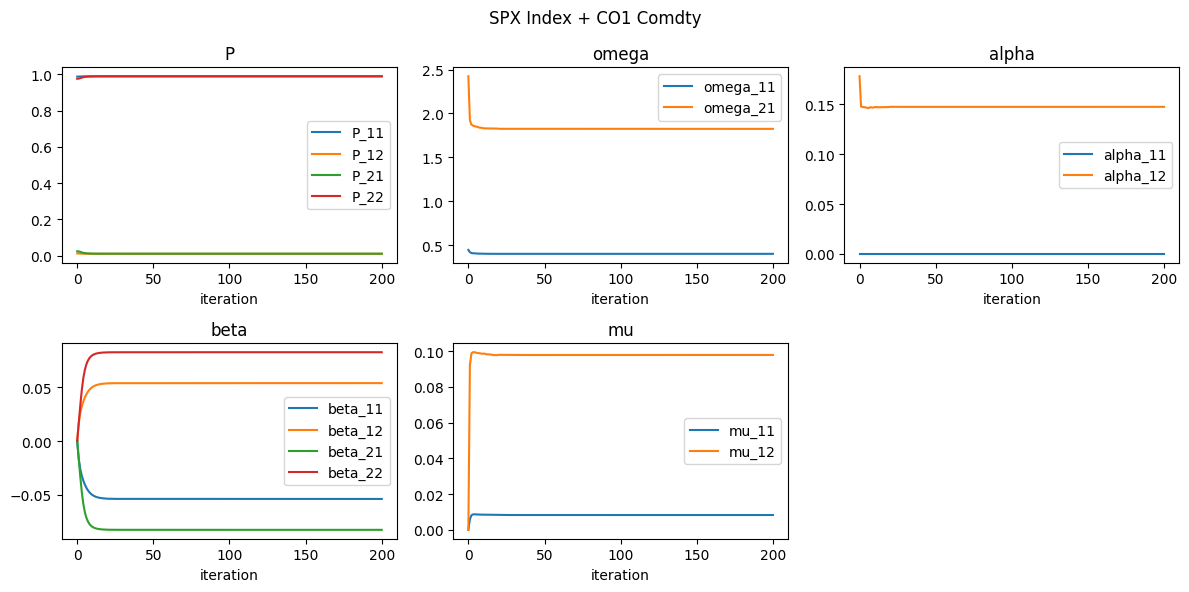

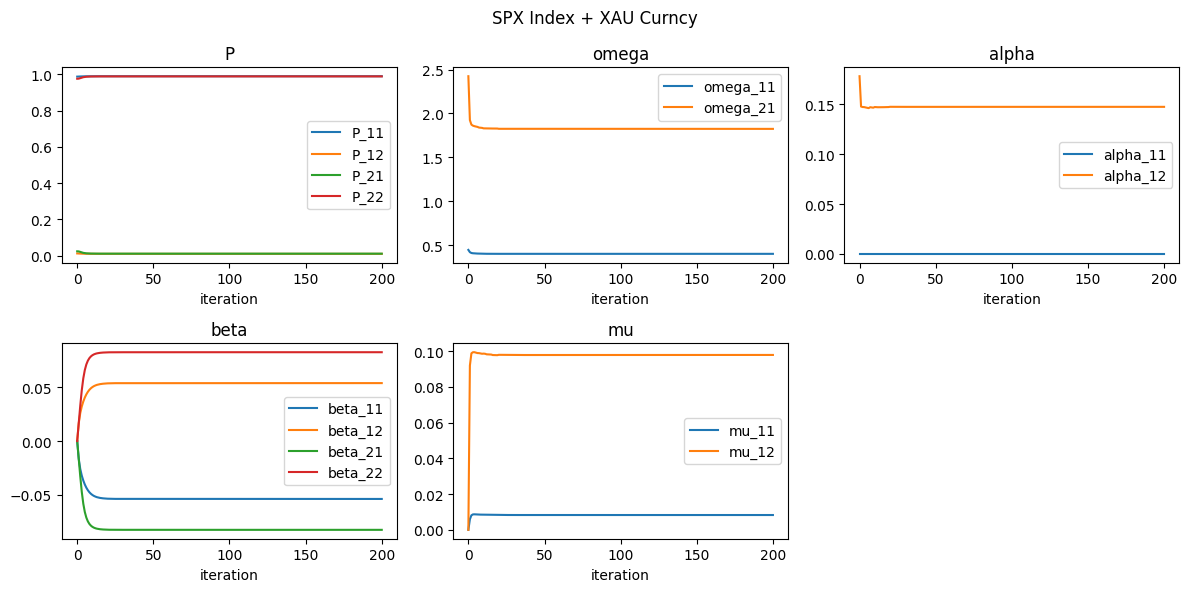

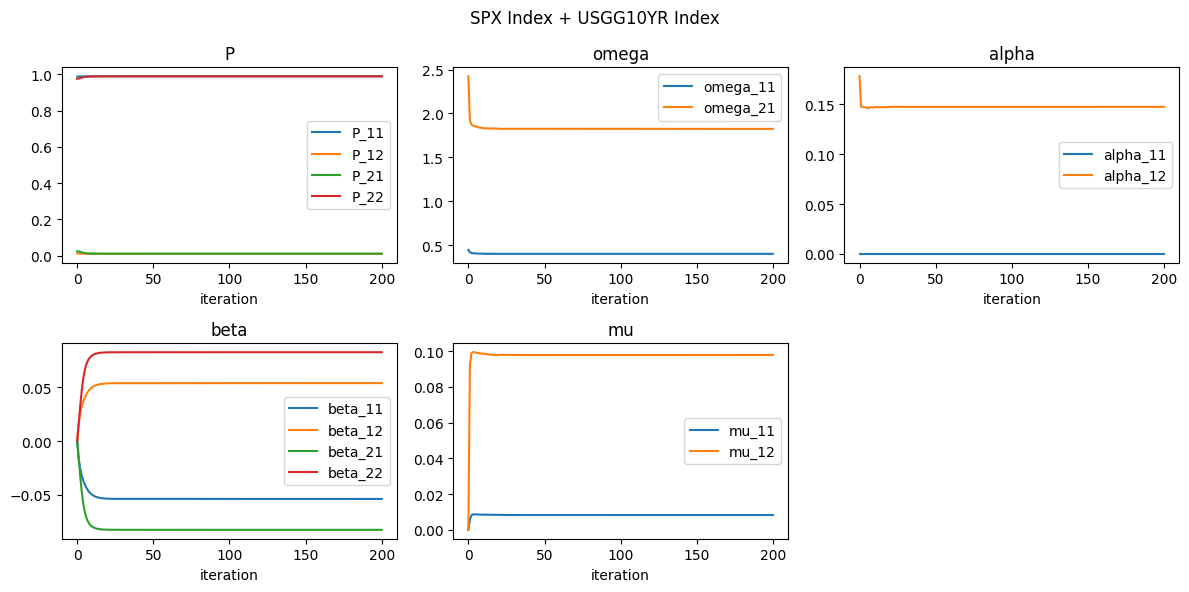

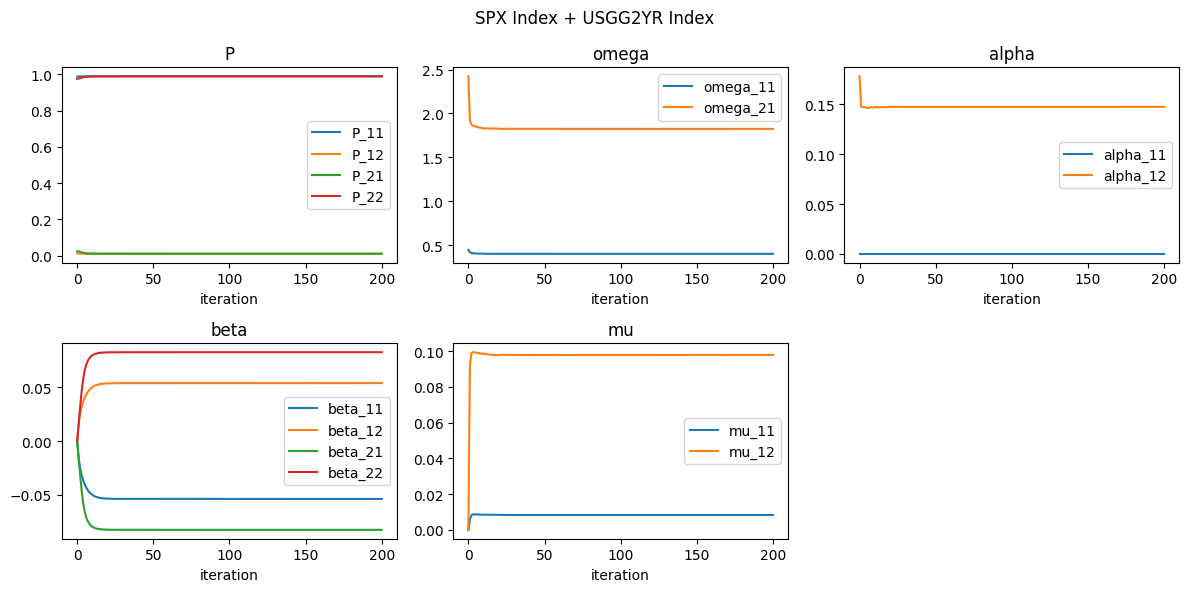

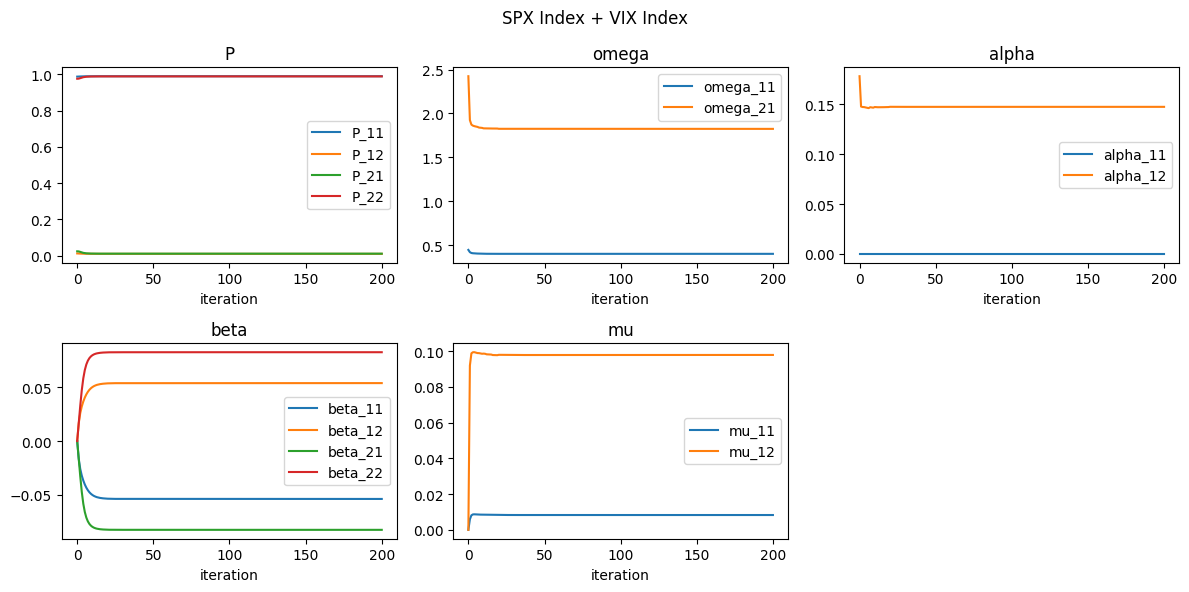

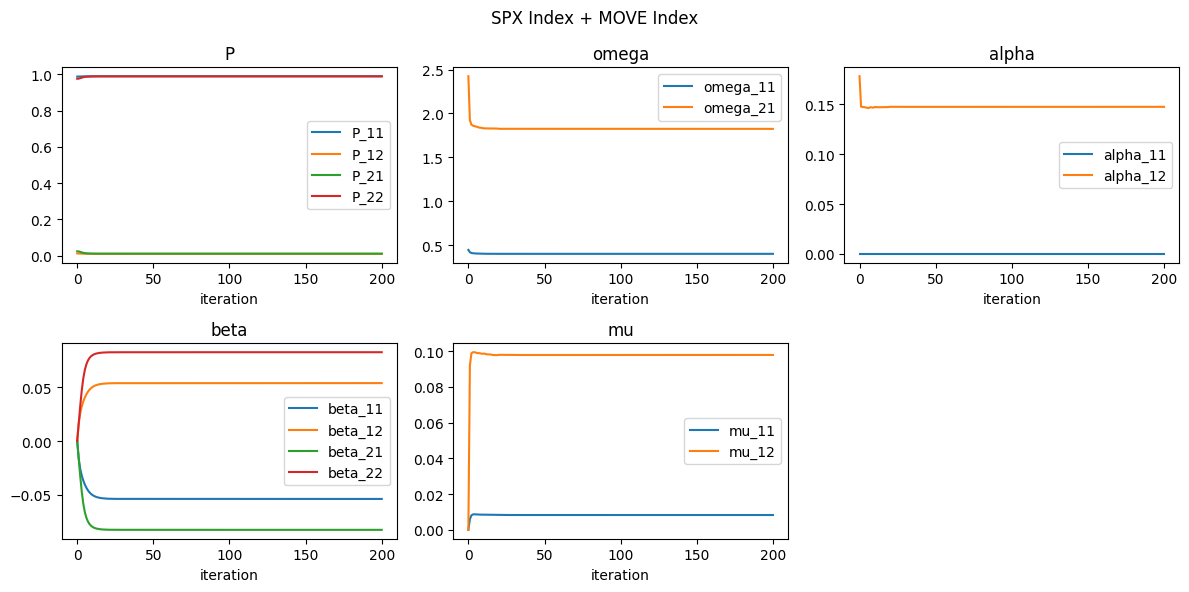

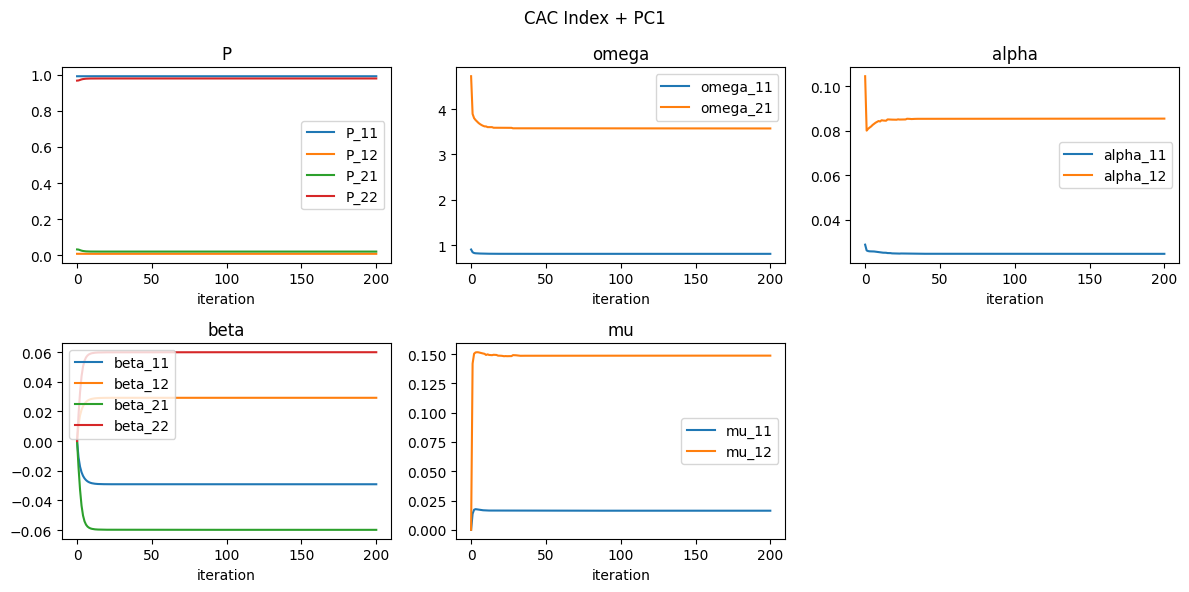

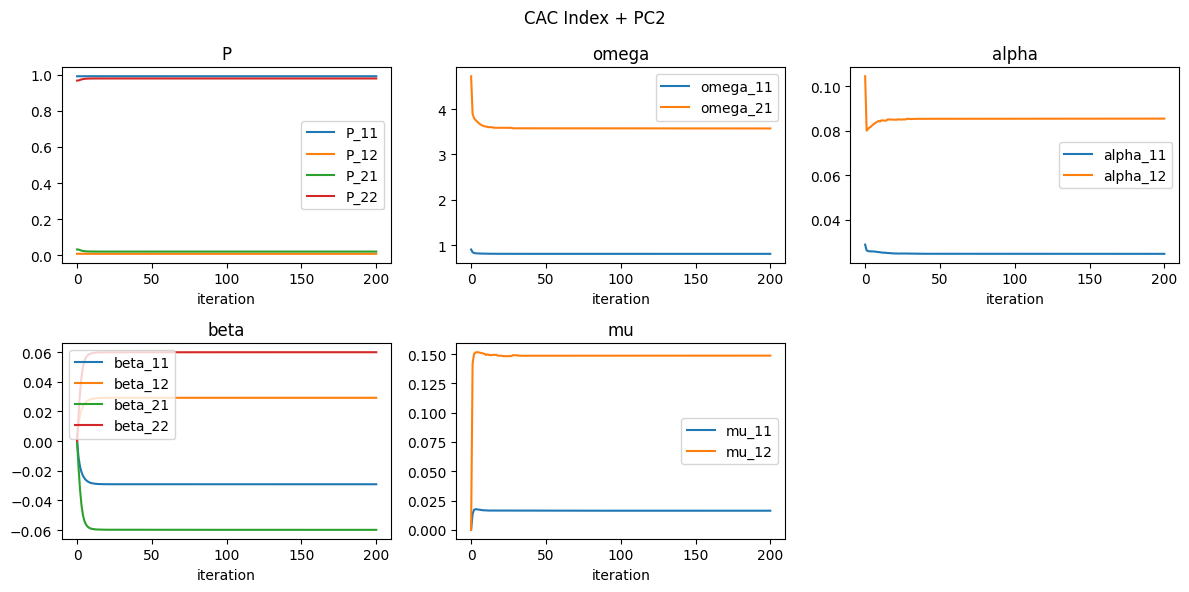

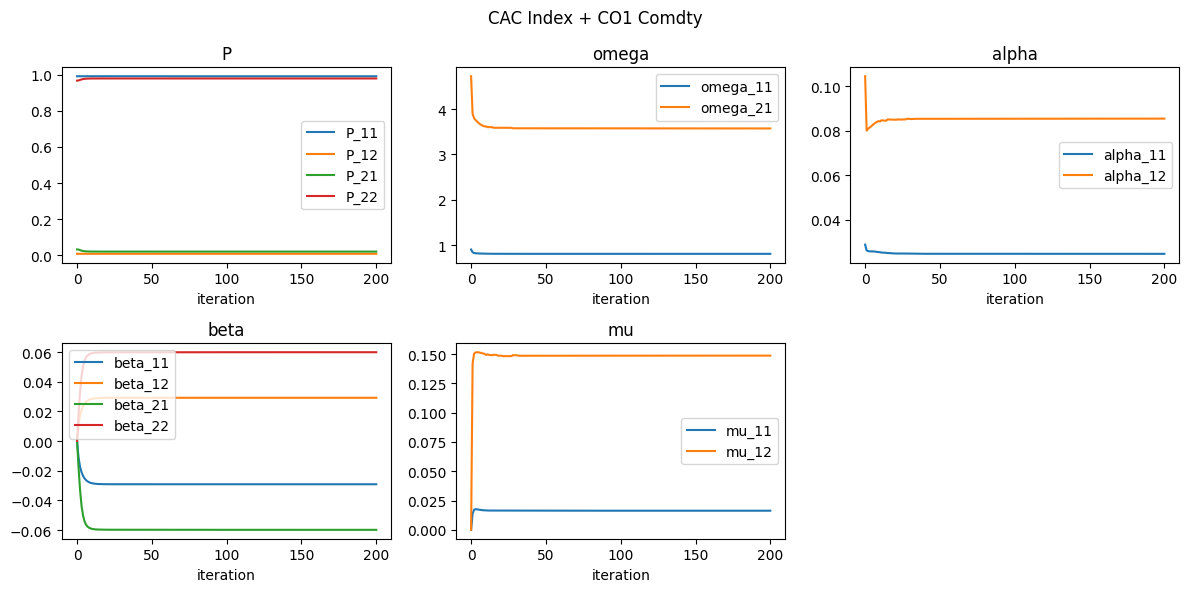

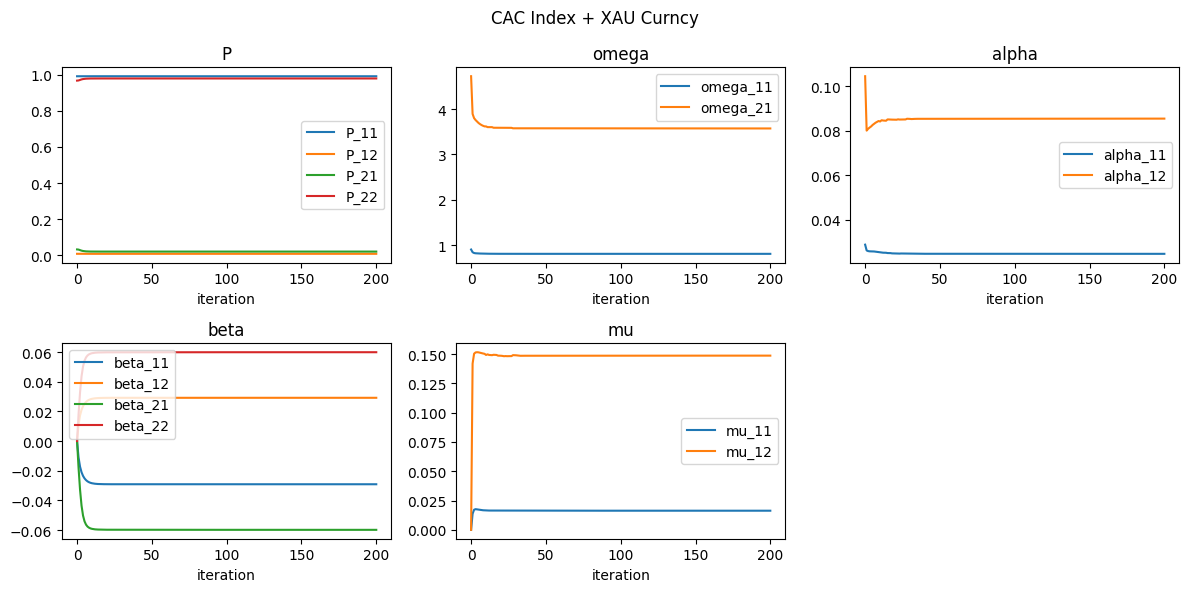

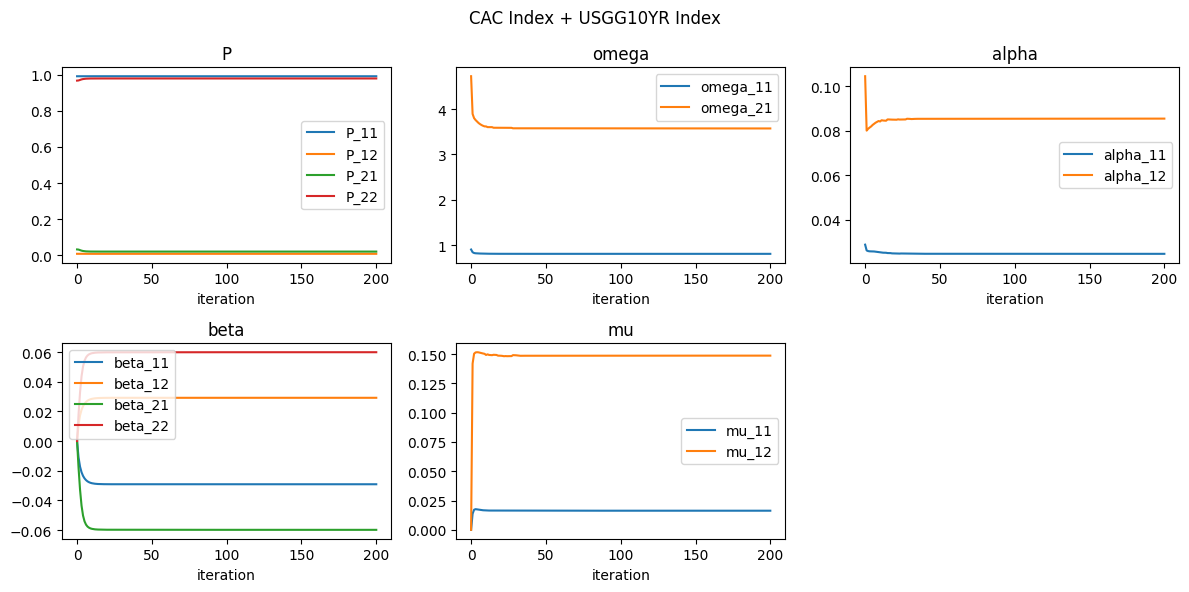

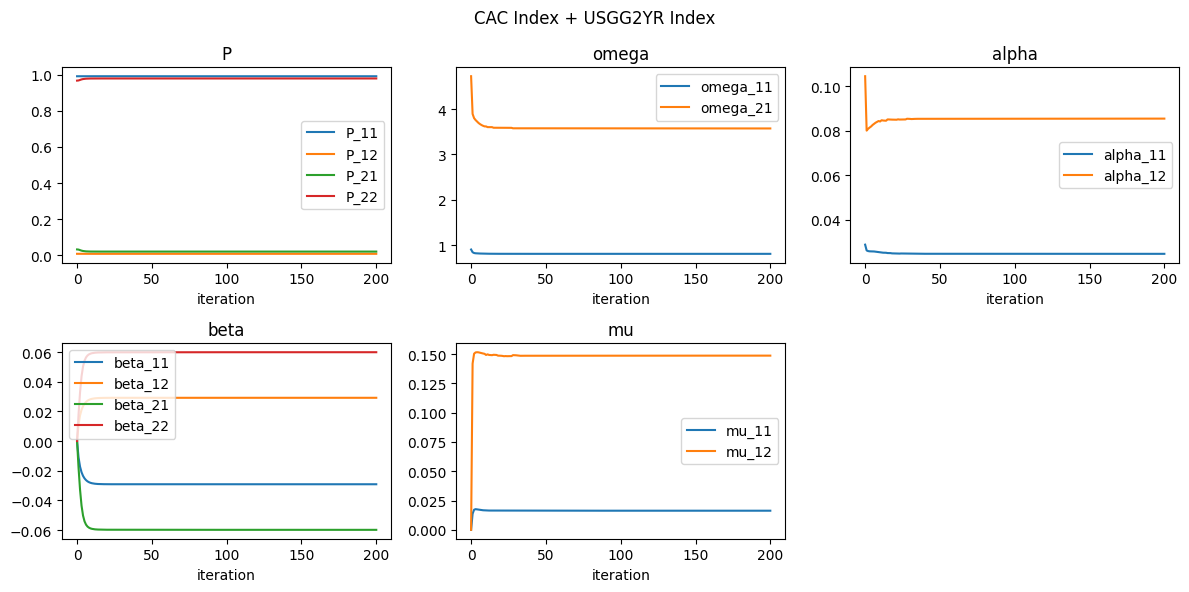

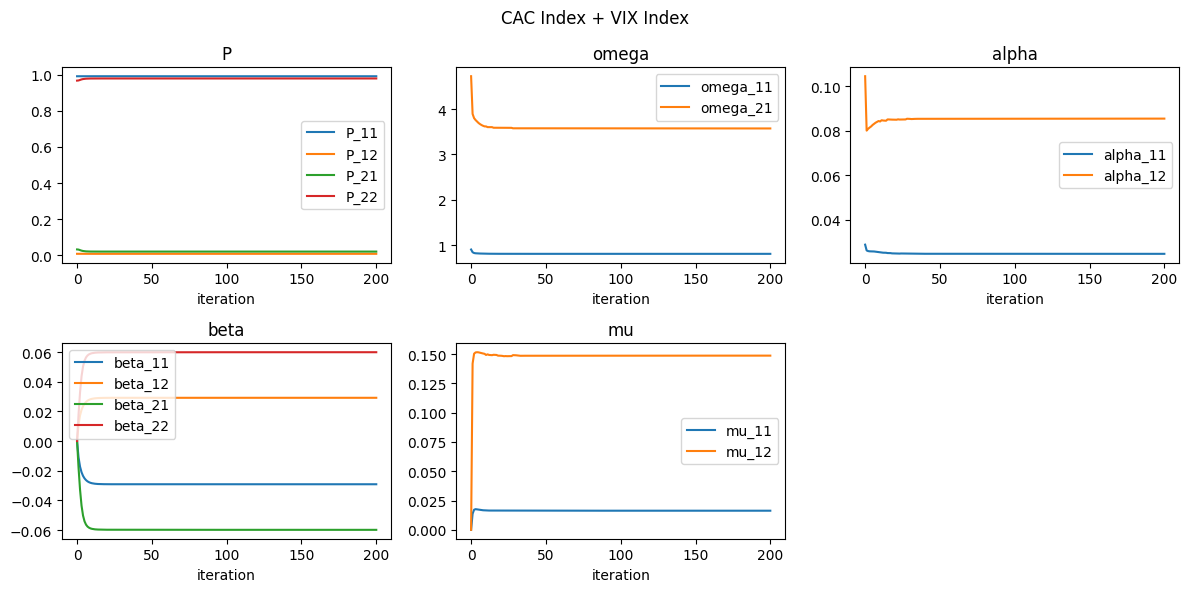

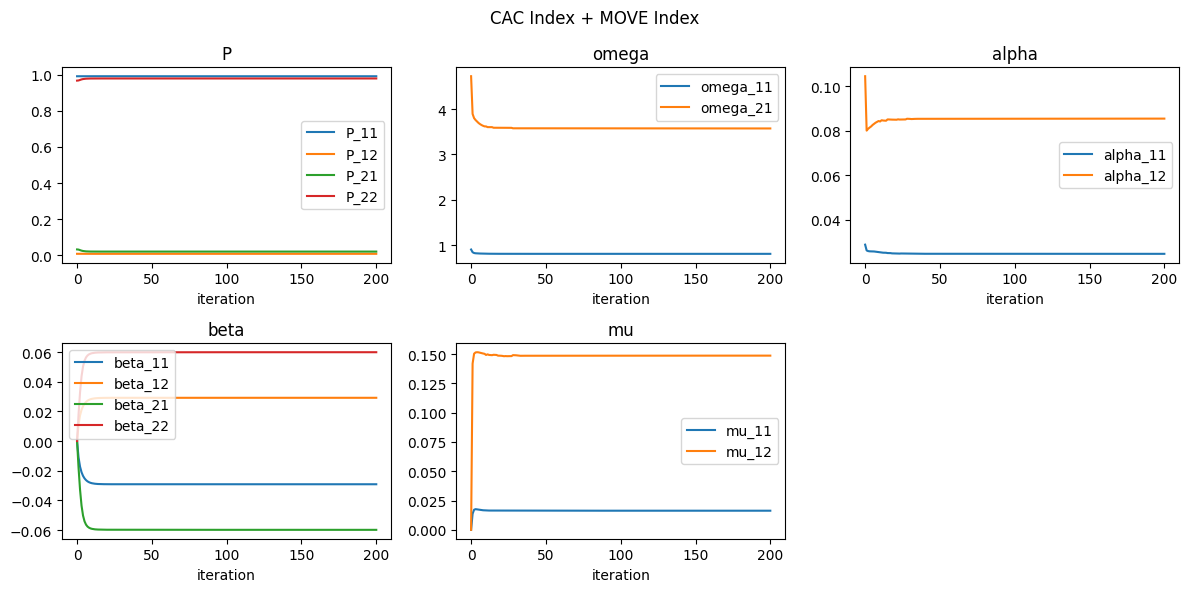

In [ ]:

for target in targets[:2]:
    for indicator in viable_indicators:
        results = copy(stored_data[target][viable_indicators[0]]['result'])
        results[0] = {key:value for key,value in results[0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive']}
        #result_exogen[0].pop('mu_depends_on_delta')
        df_exo = convert_dict_to_dataframe(results)
        fig,axs = plt.subplots(2,3,figsize=(12,12))
        plt.suptitle(f'{target} + {indicator}')
        for idx,start in enumerate(['P','omega','alpha','beta','mu']):
            ax = axs[idx//3,idx%3]
            df_exo.loc[:200].plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6),ax=ax)
            ax.set_title(start)
        fig.delaxes(axs[1,2])
        plt.tight_layout()
        plt.show()

### Useless Analytics

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

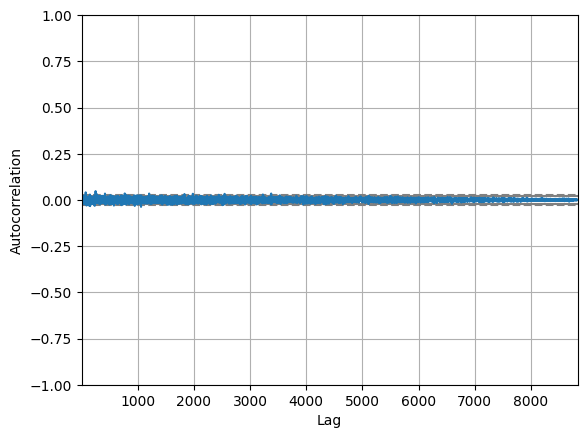

In [108]:
pd.plotting.autocorrelation_plot(data['VIX Index'])

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

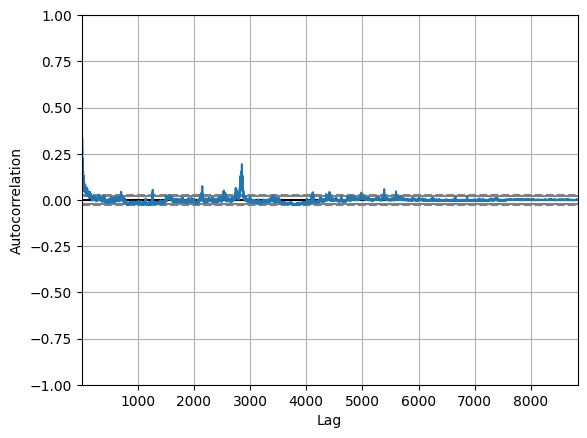

In [115]:
pd.plotting.autocorrelation_plot(data['SPX Index']**2)

(0.0, 20.0)

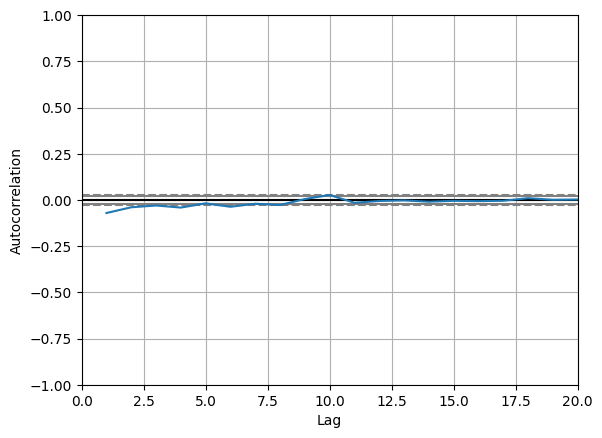

In [125]:
pd.plotting.autocorrelation_plot(PCA_df['PC1'])
plt.xlim(0,20)

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

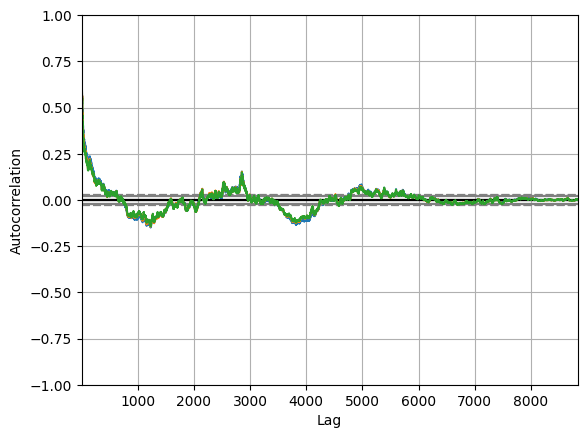

In [113]:
pd.plotting.autocorrelation_plot(Sigmas['SPX Index']['VIX Index'])
pd.plotting.autocorrelation_plot(Sigmas['SPX Index']['No Exogeneous'])
pd.plotting.autocorrelation_plot(Sigmas['SPX Index']['MOVE Index'])

In [173]:
np.mean(Sigmas[target][indicator]*252/10**4)

0.07045260444060952

In [178]:
o = pd.read_excel(DATA / 'data.xlsx').loc[1:]

In [180]:
o.columns = o.loc[1]

In [183]:
o.iloc[1:]['VIX Index']

2       27.37
3       28.45
4       30.57
5       33.82
6       29.65
        ...  
8829    20.26
8830    20.11
8831    19.22
8832    18.19
8833    17.24
Name: VIX Index, Length: 8832, dtype: object

In [192]:
test = stored_data['SPX Index']['VIX Index']
test['initial_params']

{'P': array([[0.98792576, 0.01207424],
        [0.02378743, 0.97621257]]),
 'omega': array([0.44455905, 2.42397447]),
 'alpha': array([[0.        , 0.17830011]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -12040.120902805154,
 'exogen_transition': array([[  5.36397273],
        [  5.5079411 ],
        [  4.52658002],
        ...,
        [-10.10332076],
        [ -7.18709753],
        [ -3.87006375]]),
 'exogen_additive': array([[ 5.36397273],
        [ 5.5079411 ],
        [ 4.52658002],
        ...,
        [10.10332076],
        [ 7.18709753],
        [ 3.87006375]]),
 'mu': array([[0., 0.]]),
 'beta': array([[[0.],
         [0.]],
 
        [[0.],
         [0.]]])}

In [199]:
probas = np.array([get_transition_matrix(test['final_result']['P'],test['initial_params']['exogen_transition'][t-1],test['final_result']['beta']) for t in range(1,len(test['eps']))])

In [ ]:
get_transition_matrix(test['final_result']['P'],test['initial_params']['exogen_transition'][t-1],test['final_result']['beta'])

In [223]:
test['initial_params']['exogen_transition'][407-1]

array([5.25762104])

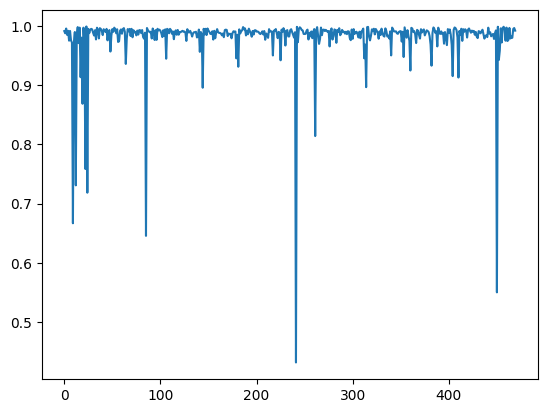

In [422]:
i,j = 0,0
plt.plot(probas[7530:8000,i,j])

In [416]:
data.index[7535]

Timestamp('2020-02-18 00:00:00')

(400.0, 500.0)

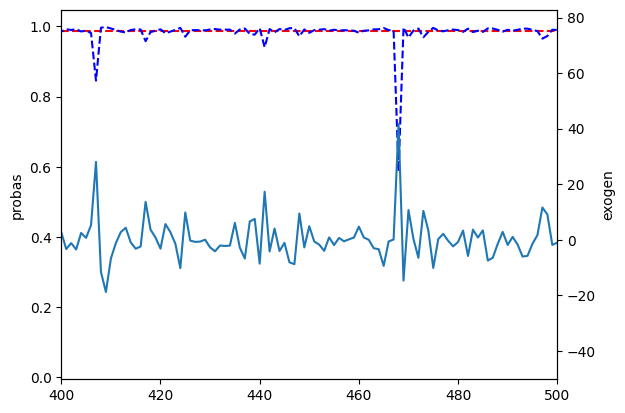

In [244]:
indicator = 'VIX Index'
i,j = 0,0
fig, ax1 = plt.subplots()
ax1.axhline(stored_data['SPX Index'][indicator]['initial_params']['P'][i,j],linestyle='--',color='r')
ax1.plot(probas[:,i,j],label='Transition Matrix',color='b',linestyle='--')
ax1.set_ylabel('probas')
ax2 = ax1.twinx()
ax2.set_ylabel('exogen')
ax2.plot(stored_data['SPX Index'][indicator]['initial_params']['exogen_transition'][:-1])
plt.xlim(400,500)

(460.0, 470.0)

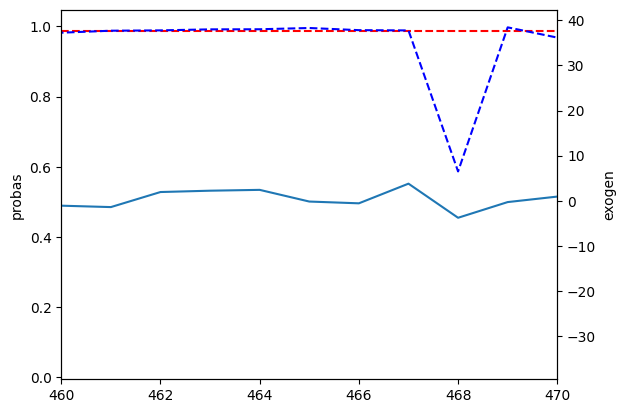

In [221]:
i,j = 0,0
fig, ax1 = plt.subplots()
ax1.axhline(stored_data['SPX Index'][indicator]['initial_params']['P'][i,j],linestyle='--',color='r')
ax1.plot(probas[:,i,j],label='Transition Matrix',color='b',linestyle='--')
ax1.set_ylabel('probas')
ax2 = ax1.twinx()
ax2.set_ylabel('exogen')
ax2.plot(stored_data['SPX Index'][indicator]['initial_params']['exogen_transition'][:-1])
plt.xlim(460,470)

(400.0, 600.0)

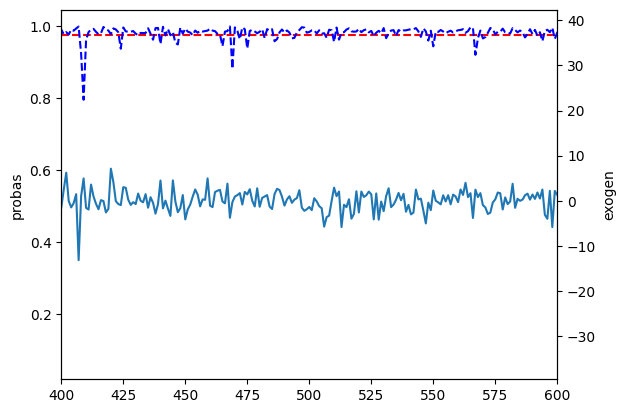

In [214]:
i,j = 1,1
fig, ax1 = plt.subplots()
ax1.axhline(stored_data['SPX Index'][indicator]['initial_params']['P'][i,j],linestyle='--',color='r')
ax1.plot(probas[:,i,j],label='Transition Matrix',color='b',linestyle='--')
ax1.set_ylabel('probas')
ax2 = ax1.twinx()
ax2.set_ylabel('exogen')
ax2.plot(stored_data['SPX Index'][indicator]['initial_params']['exogen_transition'])
plt.xlim(400,600)

In [151]:
for target in targets:
    dico = {indicator : max((stored_data[target][indicator]['final_result']['beta']*stored_data[target][indicator]['data'].std()).reshape(-1)) for indicator in stored_data[target].keys()}
    print(list(dico.keys())[np.argmax(dico.values())],max(dico.values()))

CO1 Comdty 0.5378470230684769
CO1 Comdty 0.5265137279458588
MOVE Index 0.5085548622655117
CO1 Comdty 0.5721086290490511
VIX Index 0.5856139102870305
XAU Curncy 0.3085692822701583
VIX Index 0.6489091407929994
PC2 0.4727407062741839


In [153]:
for target in targets:
    dico = {indicator : max((stored_data[target][indicator]['final_result']['mu']*stored_data[target][indicator]['data'].std()).reshape(-1)) for indicator in stored_data[target].keys()}
    print(list(dico.keys())[np.argmax(dico.values())],max(dico.values()))

CO1 Comdty 0.7657683793251958
CO1 Comdty 1.3012284568081616
MOVE Index 1.0603161944976627
CO1 Comdty 0.8568867756869358
VIX Index 1.1484872420734815
XAU Curncy 1.732575146446937
VIX Index 0.7944599504540034
PC2 0.365244946706412


In [152]:
for target in targets:
    dico = {indicator : max((stored_data[target][indicator]['final_result']['beta']).reshape(-1)) for indicator in stored_data[target].keys()}
    print(list(dico.keys())[np.argmax(dico.values())],max(dico.values()))

CO1 Comdty 0.2600501396237367
CO1 Comdty 0.24300318649647829
MOVE Index 0.23471458668501174
CO1 Comdty 0.2719755872369266
VIX Index 0.2702798402077836
XAU Curncy 0.15715259276867463
VIX Index 0.2994926449013797
PC2 0.2664705456475006


In [164]:
for target in targets:
    dico = {indicator : max((stored_data[target][indicator]['final_result']['mu']*stored_data[target][indicator]['initial_params']['exogen_additive'].mean()).reshape(-1)) for indicator in stored_data[target].keys()}
    print(list(dico.keys())[np.argmax(dico.values())],max(dico.values()))

CO1 Comdty 0.4559394572748123
CO1 Comdty 0.8048117687635162
MOVE Index 0.6313135973112022
CO1 Comdty 0.5101914652011939
VIX Index 0.6838107500592638
XAU Curncy 1.221376043547706
VIX Index 0.5029005418440177
PC2 0.24854150474845327


In [166]:
for target in targets:
    dico = {indicator : max((stored_data[target][indicator]['final_result']['omega']).reshape(-1)) for indicator in stored_data[target].keys()}
    print(list(dico.keys())[np.argmax(dico.values())],max(dico.values()))

CO1 Comdty 2.3713291293729153
CO1 Comdty 4.4165072287501355
MOVE Index 4.212423204056638
CO1 Comdty 2.3561834040706597
VIX Index 3.3311884391051323
XAU Curncy 4.149245937275571
VIX Index 2.878285098311027
PC2 5.497589445054444


In [149]:
list(dico.keys())[np.argmax(dico.values())]

'CO1 Comdty'

In [ ]:
{indicator : max((stored_data[target][indicator]['final_result']['beta']*stored_data[target][indicator]['data'].std()).reshape(-1)) for indicator in stored_data[target].keys()}

{'VIX Index': 0.4338501093498073,
 'CO1 Comdty': 0.07218443279090549,
 'PC1': 0.4192160927663704,
 'MOVE Index': 0.27409474339339696,
 'USGG10YR Index': 0.6489091407929994,
 'XAU Curncy': 0.26208311470351053,
 'USGG2YR Index': 0.473267135254782,
 'PC2': 0.3659295860332865}

States Classification

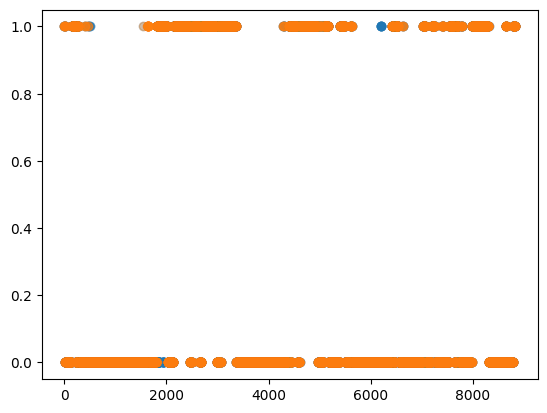

In [258]:
for indicator in list(stored_data[target].keys())[:2]:
    plt.plot(stored_data['SPX Index'][indicator]['states sequence'],label=indicator,marker='o',linestyle='',alpha=0.3)
    #plt.plot(stored_data['SPX Index']['indicator']['states sequence'],label=indicator,marker='x',linestyle='',alpha=0.5)

In [338]:
stored_data['SPX Index'][indicator].keys()

dict_keys(['data', 'eps', 'target', 'indicator', 'initial_params', 'result', 'final_result', 'states sequence'])

<Axes: >

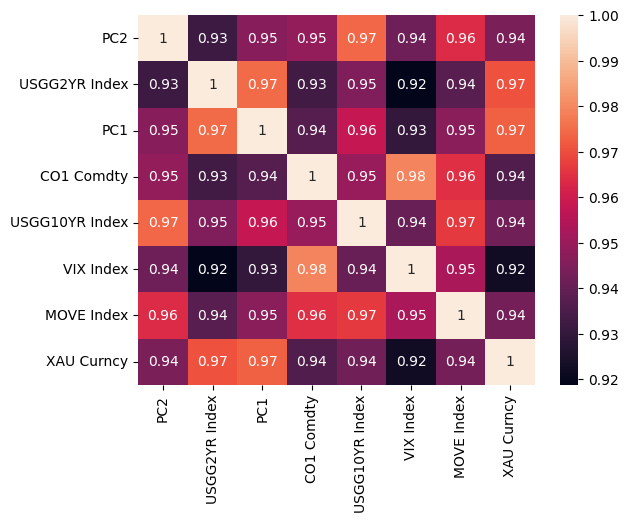

In [271]:
sns.heatmap(pd.DataFrame(np.concatenate([stored_data['SPX Index'][indicator]['states sequence'].reshape(-1,1) for indicator in stored_data['SPX Index'].keys()],axis=1),columns=stored_data[target].keys()).corr(),annot=True)

In [273]:
dff = pd.DataFrame(np.concatenate([stored_data['SPX Index'][indicator]['states sequence'].reshape(-1,1) for indicator in stored_data['SPX Index'].keys()],axis=1),columns=stored_data[target].keys())

In [274]:
dff['VIX Index'].mean()

0.33733439021628353

In [277]:
(dff['USGG2YR Index'] == dff['VIX Index']).mean()

0.9637640131355453

In [278]:
(dff['USGG2YR Index'] > dff['VIX Index']).mean()

0.01698561884271317

In [279]:
(dff['USGG2YR Index'] < dff['VIX Index']).mean()

0.01925036802174159

In [280]:
dff['USGG2YR Index'].mean()

0.3350696410372551

In [287]:
np.sqrt(Sigmas['SPX Index']['VIX Index']*252/10**4).mean()

0.16573521451623172

In [306]:
{indicator : np.sqrt(Sigmas['SPX Index'][indicator]*252/10**4).std() for indicator in stored_data['SPX Index'].keys()}

{'CO1 Comdty': 0.07021583604999758,
 'USGG2YR Index': 0.07225052611933866,
 'USGG10YR Index': 0.07058547573718194,
 'PC1': 0.06947573288252874,
 'XAU Curncy': 0.07002874543372538,
 'VIX Index': 0.0694043547662545,
 'MOVE Index': 0.07042563206472717,
 'PC2': 0.07097896952621643}

In [305]:
np.sqrt(np.var(data['SPX Index'])*252/10**4)

0.18239741028073694

Idée : probas de changement la veille des changements de régime

In [341]:
stored_data['SPX Index']['VIX Index']['states sequence']

array([1, 1, 1, ..., 1, 1, 1])

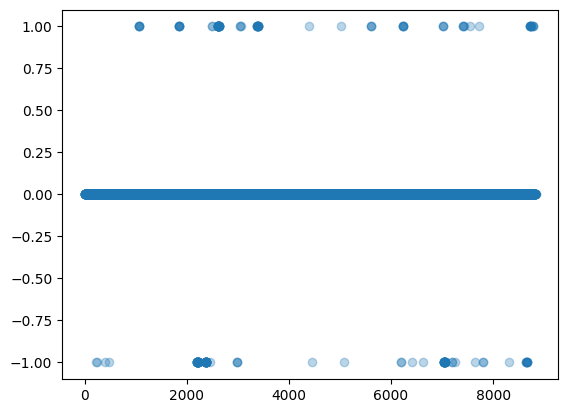

In [348]:
plt.plot(stored_data['SPX Index']['VIX Index']['states sequence']-stored_data['SPX Index']['MOVE Index']['states sequence'],linestyle='',marker='o',alpha=0.3)

In [349]:
number_of_transitions = defaultdict(lambda: defaultdict(int))
for target in targets:
    for indicator in stored_data[target].keys():
        states_sequence = stored_data[target][indicator]['states sequence']
        for i in range(1, len(states_sequence)):
            if states_sequence[i] != states_sequence[i - 1]:
                number_of_transitions[target][indicator] += 1

In [357]:
number_of_stable_transitions = defaultdict(lambda: defaultdict(int))
for target in targets:
    for indicator in stored_data[target].keys():
        states_sequence = stored_data[target][indicator]['states sequence']
        for i in range(5, len(states_sequence)):
            if states_sequence[i] != states_sequence[i - 1] and len(np.unique(states_sequence[i - 5: i - 1]))== 1:
                number_of_stable_transitions[target][indicator] += 1

In [380]:
number_of_common_transitions = defaultdict(lambda: defaultdict( lambda: defaultdict(int)))
index_of_common_transitions = defaultdict(lambda: defaultdict( lambda: defaultdict(list)))
for target in targets:
    for indicator1 in stored_data[target].keys():
        for indicator2 in stored_data[target].keys():
            states_sequence_1 = stored_data[target][indicator1]['states sequence']
            states_sequence_2 = stored_data[target][indicator2]['states sequence']
            for i in range(1,len(states_sequence_1)):
                if states_sequence_1[i] != states_sequence_1[i - 1] and states_sequence_2[i] != states_sequence_2[i - 1]:
                    number_of_common_transitions[target][indicator1][indicator2] += 1
                    index_of_common_transitions[target][indicator1][indicator2].append(i)

In [405]:
target = 'SPX Index'
indicator1 = 'PC1'
indicator2 = 'PC2'
pi1,pi2 = MS_hamilton_filter(stored_data[target][indicator1]['eps'],stored_data[target][indicator1]['result'],i=200)[0],\
          MS_hamilton_filter(stored_data[target][indicator2]['eps'],stored_data[target][indicator2]['result'],i=200)[0]
#index_of_common_transitions[target][indicator1][indicator2]

In [406]:
Results.query('target == "SPX Index"').query('indicator == @indicator1 or indicator == @indicator2')

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
67,SPX Index,PC1,10,4,-12010.017907,24040.035814,24110.896050,60.205991,2.625677e-12,0.052542,0.276807,0.836854,0.002080,0.125945,0.002542,1.138753
71,SPX Index,PC2,10,4,-12025.150117,24070.300233,24141.160468,29.941572,5.030330e-06,0.052202,0.345592,0.821432,0.001025,0.125461,0.002202,1.149230


In [409]:
for t in index_of_common_transitions[target][indicator1][indicator2]:
    print(pi1[t+1,t].max(),pi1[t+1,-1].max(),t)

0.9689294652204926 0.6593528969897166 146
0.9697175028161935 0.6029569830382491 249
0.9327824867946436 0.5723823635955492 281
0.9594837930002834 0.9477966184963917 407
0.7969251401061935 0.9250158461450987 410
0.9809758639200575 0.9995320659102219 468
0.9676047261249329 0.9562895486693339 1546
0.9840742795294934 0.8691998411882516 1809
0.9568349183214927 0.9526456534141623 1869
0.9633314110181976 0.7460363126826529 1929
0.9748078176070188 0.5565248835537412 1949
0.9628362631616014 0.707400286324485 2022
0.9691447863977369 0.6636571801165254 2138
0.971350805570676 0.7637996946861008 2501
0.9709777971988409 0.9313059113577689 2688
0.9718947532494496 0.9993265502488656 3020
0.9756294617094757 0.5449060298556168 3046
0.9725249778623776 0.8504942499937551 3069
0.9689151202101276 0.9984180029947459 4291
0.9775763324499446 0.9356518564393881 4454
0.9030613026480963 0.5632738839426228 4565
0.9589839701315593 0.9941831042187472 4610
0.9655510351273371 0.6046268522944915 4969
0.9648595904668061 

In [385]:
index_of_common_transitions['SPX Index']['CO1 Comdty']['PC1']

[146,
 410,
 468,
 1059,
 1064,
 1546,
 1548,
 1628,
 1649,
 1809,
 1869,
 1929,
 2022,
 2138,
 2501,
 2688,
 3020,
 3046,
 3069,
 3394,
 4291,
 4433,
 4454,
 4610,
 4969,
 5034,
 5082,
 5356,
 5497,
 5605,
 5629,
 6196,
 6238,
 6246,
 6413,
 6445,
 6544,
 6623,
 7072,
 7257,
 7401,
 7539,
 7771,
 7776,
 7790,
 7798]

In [366]:
number_of_transitions['SPX Index']

defaultdict(int,
            {'CO1 Comdty': 80,
             'USGG2YR Index': 66,
             'USGG10YR Index': 74,
             'PC1': 84,
             'XAU Curncy': 74,
             'VIX Index': 88,
             'MOVE Index': 76,
             'PC2': 72})

In [359]:
number_of_stable_transitions['SPX Index']

defaultdict(int,
            {'CO1 Comdty': 77,
             'USGG2YR Index': 64,
             'USGG10YR Index': 72,
             'PC1': 79,
             'XAU Curncy': 71,
             'VIX Index': 83,
             'MOVE Index': 72,
             'PC2': 70})

In [378]:
number_of_transitions['SPX Index']

defaultdict(int,
            {'CO1 Comdty': 80,
             'USGG2YR Index': 66,
             'USGG10YR Index': 74,
             'PC1': 84,
             'XAU Curncy': 74,
             'VIX Index': 88,
             'MOVE Index': 76,
             'PC2': 72})

In [377]:
MS_hamilton_filter(stored_data['SPX Index']['VIX Index']['eps'],stored_data['SPX Index']['VIX Index']['result'],i=200)[0]

array([[[0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        ...,
        [0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00]],

       [[1.00000000e-10, 1.00000000e+00],
        [2.28326485e-10, 1.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        ...,
        [0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        [5.36375152e-11, 1.00000000e+00]],

       [[0.00000000e+00, 0.00000000e+00],
        [5.57285675e-03, 9.94427143e-01],
        [6.47476532e-03, 9.93525235e-01],
        ...,
        [0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        [1.22577915e-03, 9.98774221e-01]],

       ...,

       [[0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00],
        ...,
        [5.49683194e-05, 9.99945032e-01],
     

# Annex

In [246]:
Results[['target','indicator','Log-Likelihood','sample size','sigma score']].sort_values('sample size').iloc[-13:]

,target,indicator,Log-Likelihood,sample size,sigma score
29,SPX Index,USDCHF Curncy,-12033.865167,8831,1.132105
26,SPX Index,MOVE Index,-11951.493157,8831,1.222158
25,SPX Index,USDCNY Curncy,-12035.165066,8831,1.132613
24,SPX Index,SFFRNEWS Index,-11957.154799,8831,1.390633
7,SPX Index,USDJPY Curncy,-12028.449393,8831,1.119061
21,SPX Index,XAU Curncy,-12018.570382,8831,1.142239
8,SPX Index,CO1 Comdty,-12023.242772,8831,1.180109
16,SPX Index,USGG2YR Index,-12034.080287,8831,1.171153
30,SPX Index,EURUSD Curncy,-12020.674314,8831,1.131882
14,SPX Index,No Exogenous,-12040.120903,8831,1.138112


In [255]:
Results.sort_values('sample size').iloc[-13:].sort_values('Log-Likelihood')

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,mean Log-Likelihood,sample size,mean AIC,mean BIC,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
14,SPX Index,No Exogenous,6,0,-12040.120903,24092.241806,24132.001319,0.000000,NaN,-1.363393,8831,2.728144,2.732647,0.051750,0.453104,0.790118,0.000486,0.125967,0.001750,1.138112
25,SPX Index,USDCNY Curncy,10,4,-12035.165066,24090.330132,24156.595987,9.911674,4.194210e-02,-1.362832,8831,2.727928,2.735432,0.052089,0.370791,0.830753,0.000925,0.125872,0.002089,1.132613
16,SPX Index,USGG2YR Index,10,4,-12034.080287,24088.160574,24154.426430,12.081231,1.675732e-02,-1.362709,8831,2.727682,2.735186,0.051863,0.424563,0.807733,0.000291,0.125942,0.001863,1.171153
29,SPX Index,USDCHF Curncy,10,4,-12033.865167,24087.730335,24153.996190,12.511471,1.392676e-02,-1.362684,8831,2.727633,2.735137,0.051976,0.397119,0.819576,0.000639,0.125850,0.001976,1.132105
7,SPX Index,USDJPY Curncy,10,4,-12028.449393,24076.898786,24143.164642,23.343019,1.081325e-04,-1.362071,8831,2.726407,2.733911,0.052089,0.370791,0.812740,0.001910,0.125945,0.002089,1.119061
20,SPX Index,USGG10YR Index,10,4,-12028.039104,24076.078208,24142.344063,24.163598,7.406429e-05,-1.362025,8831,2.726314,2.733818,0.051070,0.645619,0.660365,0.000414,0.125880,0.001070,1.189666
8,SPX Index,CO1 Comdty,10,4,-12023.242772,24066.485544,24132.751400,33.756261,8.360709e-07,-1.361481,8831,2.725228,2.732731,0.052542,0.276807,0.836854,0.003546,0.125833,0.002542,1.180109
30,SPX Index,EURUSD Curncy,10,4,-12020.674314,24061.348628,24127.614484,38.893178,7.329505e-08,-1.361191,8831,2.724646,2.732150,0.052655,0.256136,0.875532,0.000781,0.125411,0.002655,1.131882
21,SPX Index,XAU Curncy,10,4,-12018.570382,24057.140765,24123.406621,43.101041,9.860172e-09,-1.360952,8831,2.724169,2.731673,0.051863,0.424563,0.783405,0.001200,0.125714,0.001863,1.142239
6,SPX Index,USDGBP Curncy,10,4,-12016.642795,24053.285589,24119.551445,46.956217,1.557274e-09,-1.360734,8831,2.723733,2.731237,0.051863,0.424563,0.807733,0.000056,0.125669,0.001863,1.114828


In [256]:
stored_data['SPX Index']['VIX Index']['final_result']

{'P': array([[0.15468277, 0.84531723],
        [0.57672796, 0.42327204]]),
 'beta': array([[[-2.51497986],
         [ 2.51497986]],
 
        [[-0.75225362],
         [ 0.75225362]]]),
 'omega': array([0.26402626, 0.77199148]),
 'alpha': array([[0.        , 0.12638166]]),
 'mu': array([[0.        , 1.58535226]]),
 'pi_0': array([1.e+00, 1.e-10]),
 'log-likelihood': -11521.543889907649,
 'exogen_transition': array([[-0.01320798],
        [ 0.14658061],
        [ 0.27789935],
        ...,
        [ 1.4928683 ],
        [ 1.28436639],
        [ 1.17209357]]),
 'exogen_additive': array([[0.01320798],
        [0.14658061],
        [0.27789935],
        ...,
        [1.4928683 ],
        [1.28436639],
        [1.17209357]]),
 'mean log-likelihood': -1.3046703532904143}

In [52]:
for target in targets:
    for indicator in stored_data[target].keys():
        if indicator != 'No Exogenous':
            print(f'{target},{indicator}\n max beta:{max(stored_data[target][indicator]['final_result']['beta'].reshape(-1))}\n max mu: {max(stored_data[target][indicator]['final_result']['mu'].reshape(-1))}')

SPX Index,CESIGBP Index
 max beta:0.1928228400863044
 max mu: 0.032730061691871856
SPX Index,VIX3M Index
 max beta:0.00475342596858508
 max mu: 0.0015453504439385149
SPX Index,SMOVEU3M Index
 max beta:0.0025993374792229957
 max mu: 0.009491542545825744
SPX Index,RCHSINDX Index
 max beta:0.011181805714097874
 max mu: 0.07020327438877413
SPX Index,GTDEM2Y Govt
 max beta:2.0493631645946135
 max mu: 12.568229929769261
SPX Index,CDX IG CDSI GEN 5Y Corp
 max beta:0.1863670050392176
 max mu: 0.2640309172128681
SPX Index,USDGBP Curncy
 max beta:0.002330591558503426
 max mu: 0.006993074472412611
SPX Index,USDJPY Curncy
 max beta:0.0027498371212749313
 max mu: 0.004468053801792163
SPX Index,CO1 Comdty
 max beta:0.0024117934984205633
 max mu: 0.0038250218628464966
SPX Index,CESICNY Index
 max beta:0.12208611512728289
 max mu: 0.18525435273562374
SPX Index,VIX6M Index
 max beta:0.0031809850007464284
 max mu: 0.005519236273881502
SPX Index,CDX HY CDSI GEN 5Y SPRD Corp
 max beta:0.05138533315105811


In [47]:
stored_data['SPX Index']['VIX Index']['final_result']

{'P': array([[0.98868091, 0.01131909],
        [0.01288589, 0.98711411]]),
 'beta': array([[[-0.00336949],
         [ 0.00336949]],
 
        [[-0.00537864],
         [ 0.00537864]]]),
 'omega': array([0.39304217, 2.36177415]),
 'alpha': array([[0.        , 0.18019113]]),
 'mu': array([[0.00061036, 0.        ]]),
 'pi_0': array([1.e-10, 1.e+00]),
 'log-likelihood': -12010.456050436365,
 'exogen_transition': array([[  78.60786998],
        [  80.71975631],
        [  66.32407331],
        ...,
        [-148.28339279],
        [-105.50502498],
        [ -56.84712734]]),
 'exogen_additive': array([[ 78.60786998],
        [ 80.71975631],
        [ 66.32407331],
        ...,
        [148.28339279],
        [105.50502498],
        [ 56.84712734]]),
 'mean log-likelihood': -1.3600335239991355}

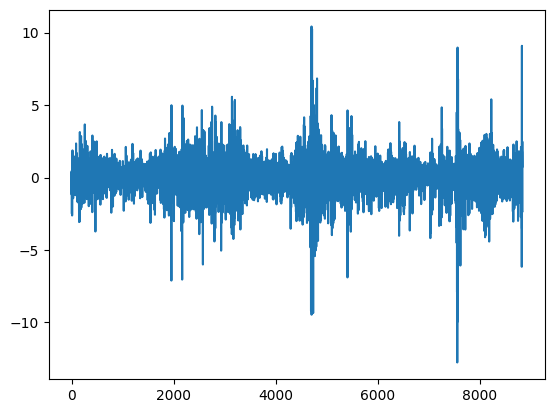

In [60]:
plt.plot(stored_data['SPX Index']['VIX Index']['eps'])

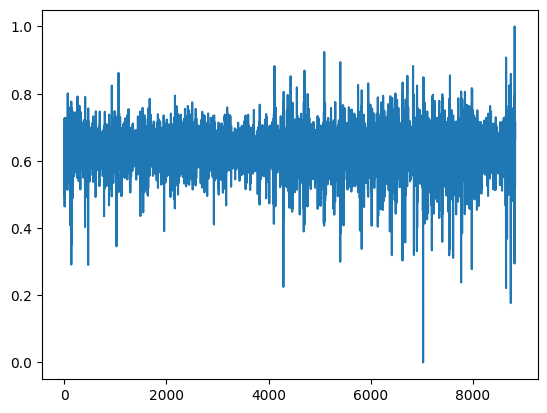

In [88]:
plt.plot(stored_data['SPX Index']['VIX Index']['data'])

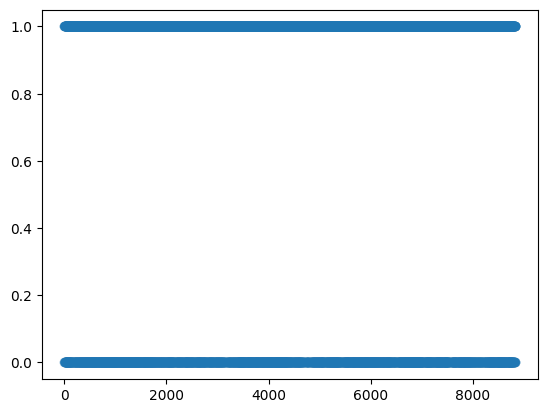

In [247]:
plt.plot(stored_data['SPX Index']['VIX Index']['states sequence'],label='VIX Index',marker='o',linestyle='',alpha=0.3)

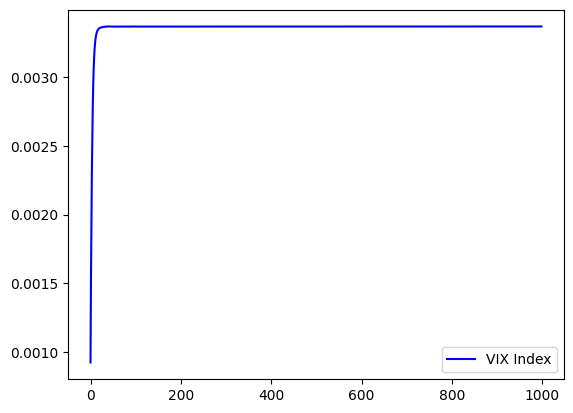

In [36]:
for indicator in ['VIX Index']:
    plt.plot([stored_data['SPX Index'][indicator]['result'][i]['beta'][0,1,0] for i in range(1,1000)],label=indicator,color='b')
    plt.legend()
    plt.show()

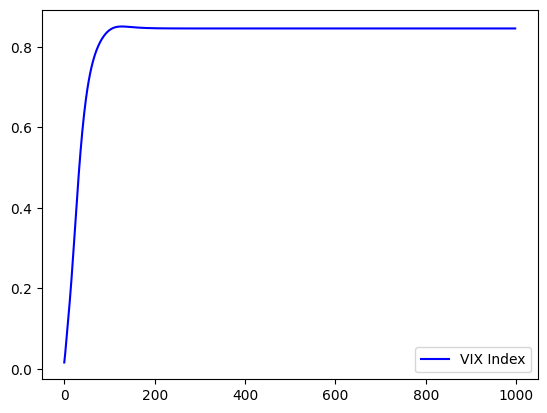

In [ ]:
for indicator in ['VIX Index']:
    plt.plot([stored_data['SPX Index'][indicator]['result'][i]['P'][0,1] for i in range(1,1000)],label=indicator,color='b')
    plt.legend()
    plt.show()

In [110]:
Results

,target,indicator,df,excess df,Log-Likelihood,AIC,BIC,LR stat,LR p-value,mean Log-Likelihood,sample size,mean AIC,mean BIC,Violation Rate,Kupiec p-value,Christoffersen p-value,DQ p-value,VaR loss,Mean Violation Error,sigma score
0,SPX Index,CESIGBP Index,10,4,-7612.380793,15244.761586,15311.027442,8.855480e+03,0.000000e+00,-1.364715,5578,2.733016,2.744896,0.053603,0.222011,0.659963,3.629138e-05,0.130020,0.003603,1.149021
1,SPX Index,VIX3M Index,10,4,-8075.009991,16170.019982,16236.285837,7.930222e+03,0.000000e+00,-1.385554,5828,2.774540,2.785910,0.054049,0.161251,0.693686,1.178801e-02,0.132379,0.004049,1.182403
2,SPX Index,SMOVEU3M Index,10,4,-10213.137000,20446.274000,20512.539856,3.653968e+03,0.000000e+00,-1.432418,7130,2.867640,2.876934,0.052875,0.269565,0.696835,1.057593e-04,0.134908,0.002875,1.243196
3,SPX Index,RCHSINDX Index,10,4,-10827.344626,21674.689252,21740.955108,2.425553e+03,0.000000e+00,-1.378577,7854,2.759701,2.768138,0.053731,0.133709,0.900822,1.744955e-05,0.128391,0.003731,5.129989
4,SPX Index,GTDEM2Y Govt,10,4,-11783.762034,23587.524068,23653.789924,5.127177e+02,0.000000e+00,-1.361970,8652,2.726251,2.733910,0.050855,0.715821,0.696897,8.817924e-04,0.126340,0.000855,1.965479
5,SPX Index,CDX IG CDSI GEN 5Y Corp,10,4,-4386.161387,8792.322773,8858.588629,1.530792e+04,0.000000e+00,-1.288910,3403,2.583698,2.603170,0.053482,0.356480,0.813301,4.749061e-02,0.120803,0.003482,1.039860
6,SPX Index,USDGBP Curncy,10,4,-12037.082382,24094.164765,24160.430620,6.077041e+00,1.934682e-01,-1.363049,8831,2.728362,2.735866,0.051297,0.577671,0.724464,2.171731e-04,0.125894,0.001297,1.125506
7,SPX Index,USDJPY Curncy,10,4,-12036.093849,24092.187698,24158.453554,8.054107e+00,8.961616e-02,-1.362937,8831,2.728138,2.735642,0.051863,0.424563,0.799026,3.490359e-03,0.125963,0.001863,1.126435
8,SPX Index,CO1 Comdty,10,4,-12034.900328,24089.800656,24156.066511,1.044115e+01,3.361736e-02,-1.362802,8831,2.727868,2.735372,0.051863,0.424563,0.756966,9.487688e-04,0.126112,0.001863,1.581915
9,SPX Index,CESICNY Index,10,4,-7237.970650,14495.941300,14562.207156,9.604301e+03,0.000000e+00,-1.358478,5328,2.720710,2.733147,0.054992,0.099608,0.690375,3.074512e-04,0.130744,0.004992,1.188093


 $Sigma_score = 1/n * \sum \log l(\epsilon_t|..) = 

 $LL = 1/n * \sum(l(\epsilon_t|\Delta_t=i)P(\Delta_t=i))$

